# 1. Surface redesign - ddG mutation visualization

Saved fig1_quadrant_scatter.png
Saved fig2_lollipop_top_hits.png
Saved fig3a/b heatmaps
Saved fig4_bubble_log2fc_reu.png


/tmp/ipykernel_1102257/1403418599.py:316: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1102257/1403418599.py:327: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
/tmp/ipykernel_1102257/1403418599.py:316: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1102257/1403418599.py:327: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")


Saved fig5_violin_chem_class.png
Saved fig6_parallel_coordinates.png


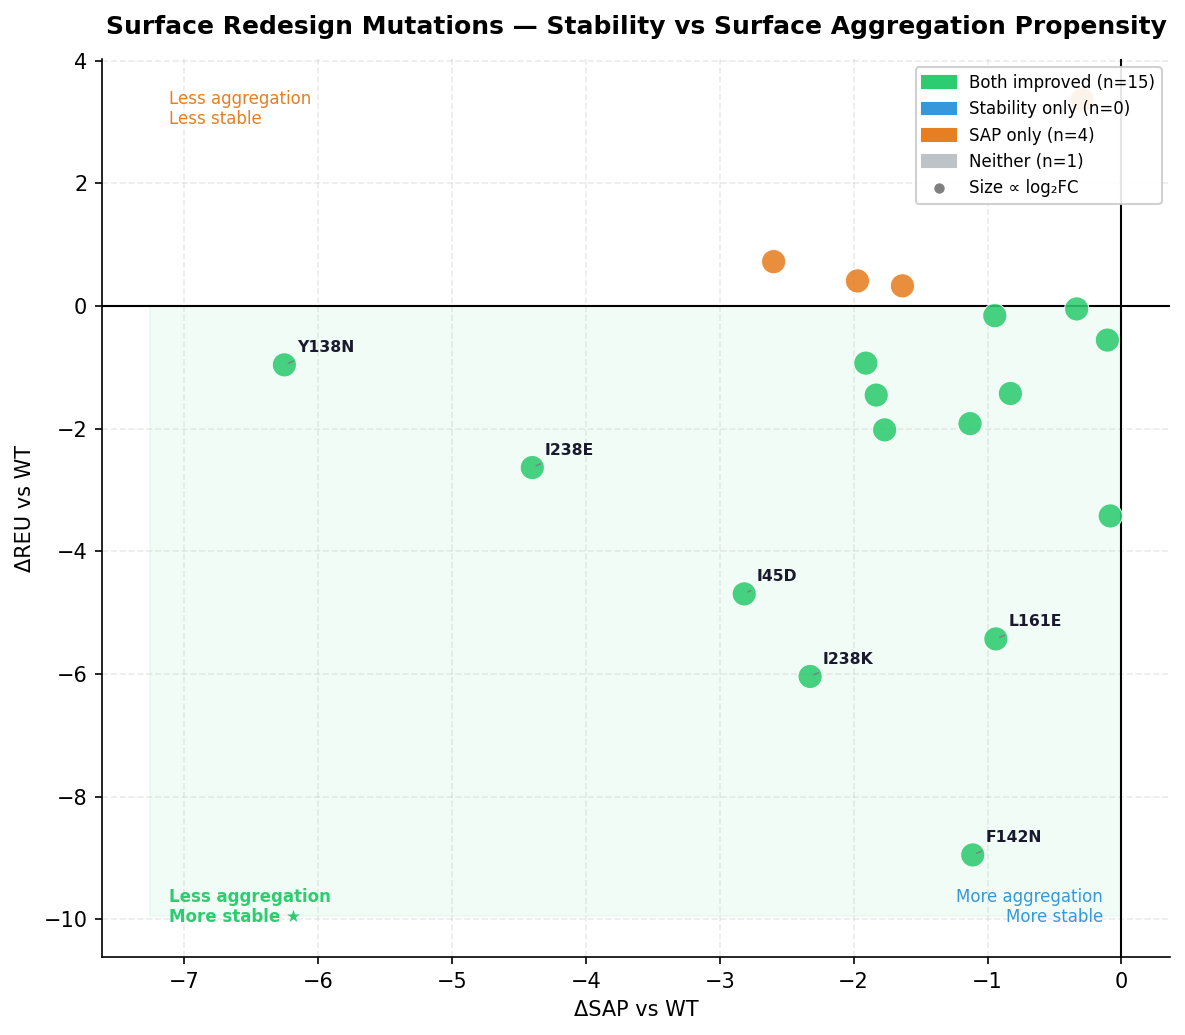

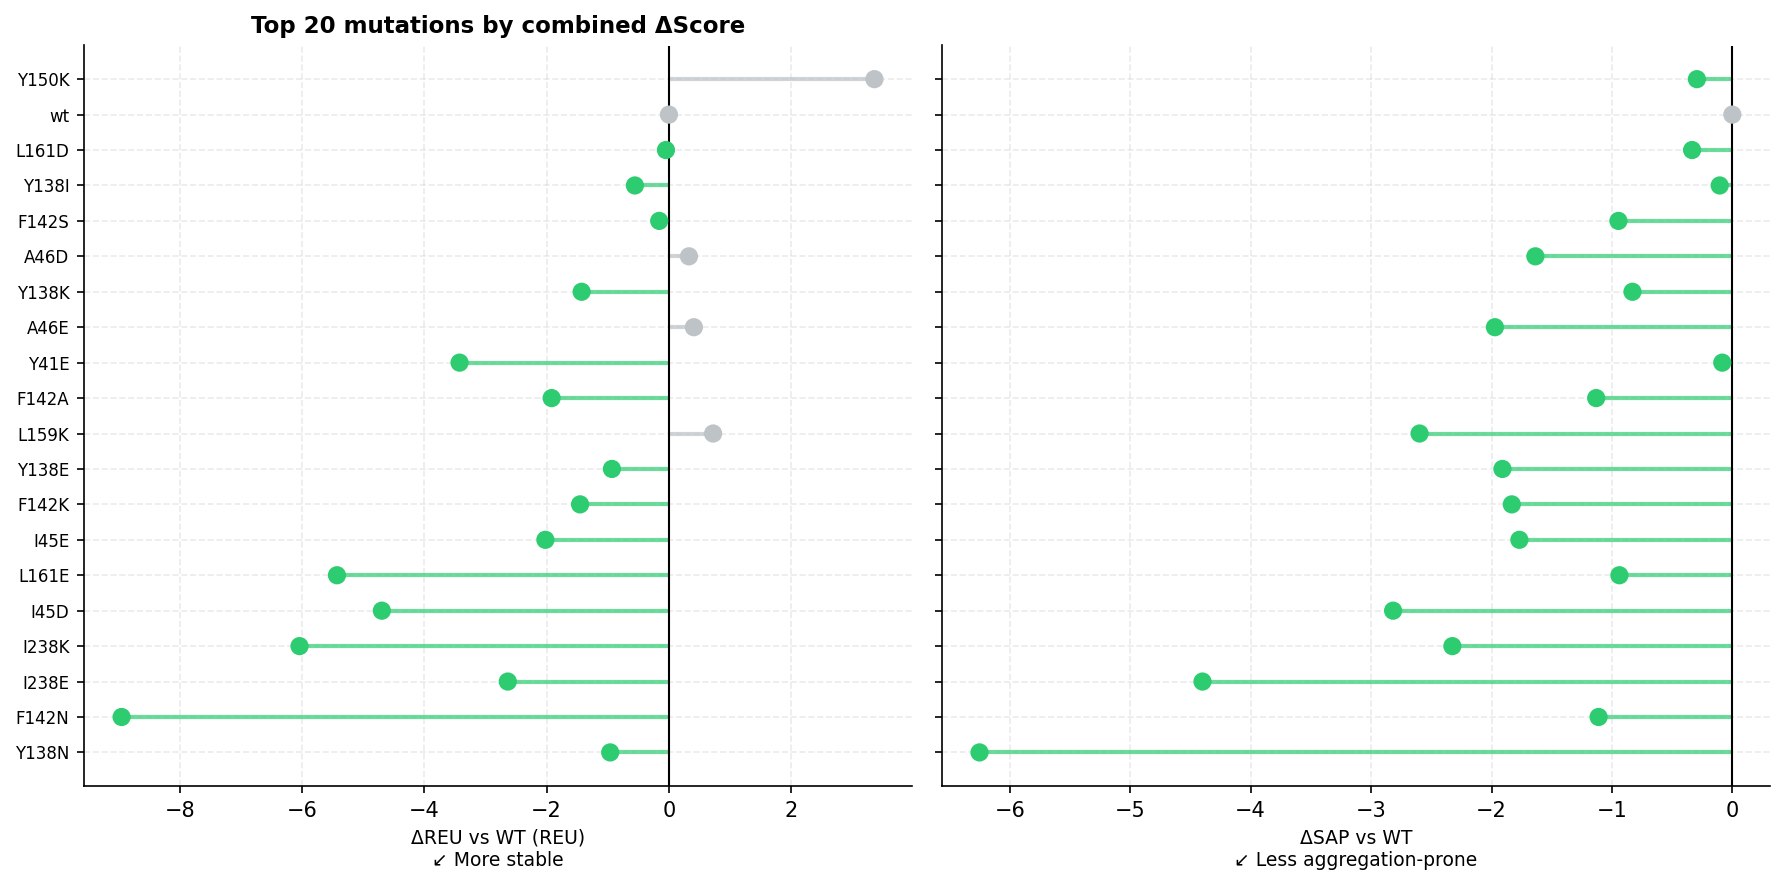

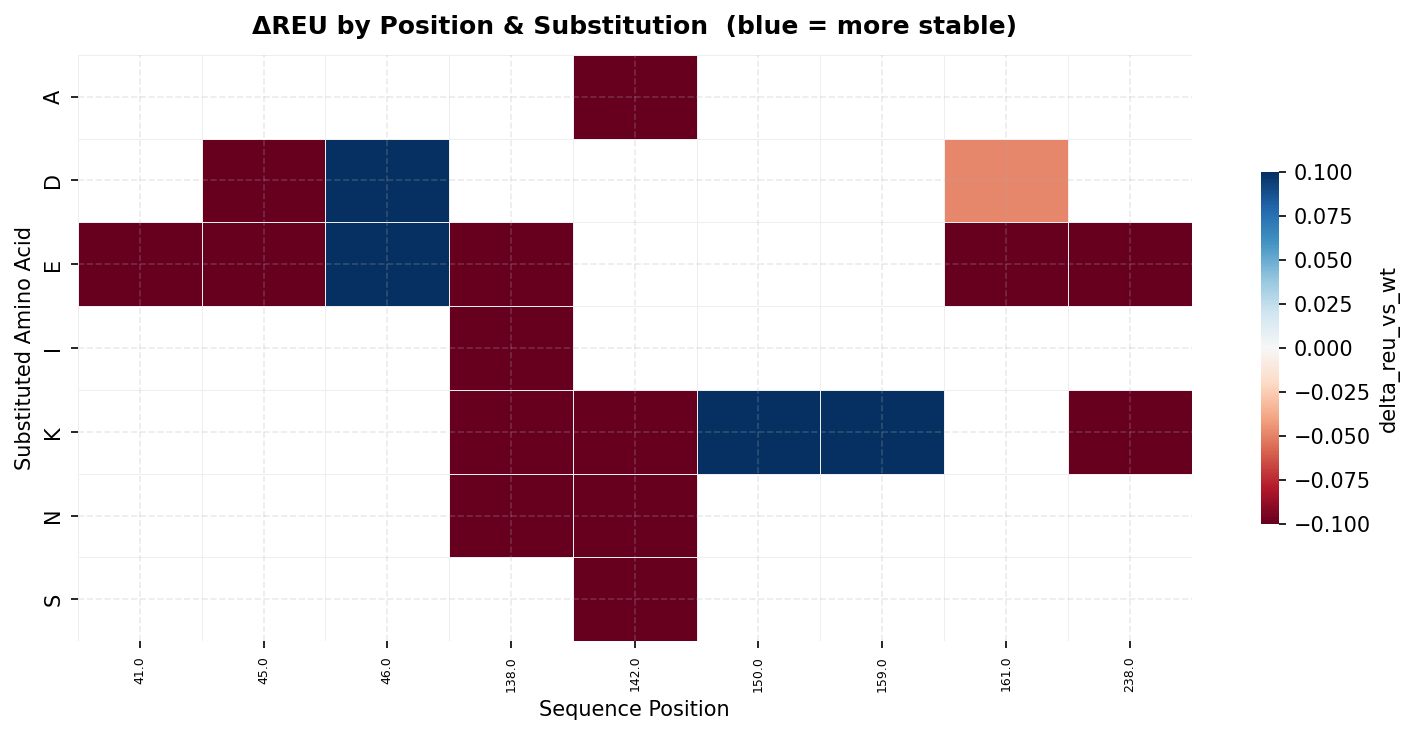

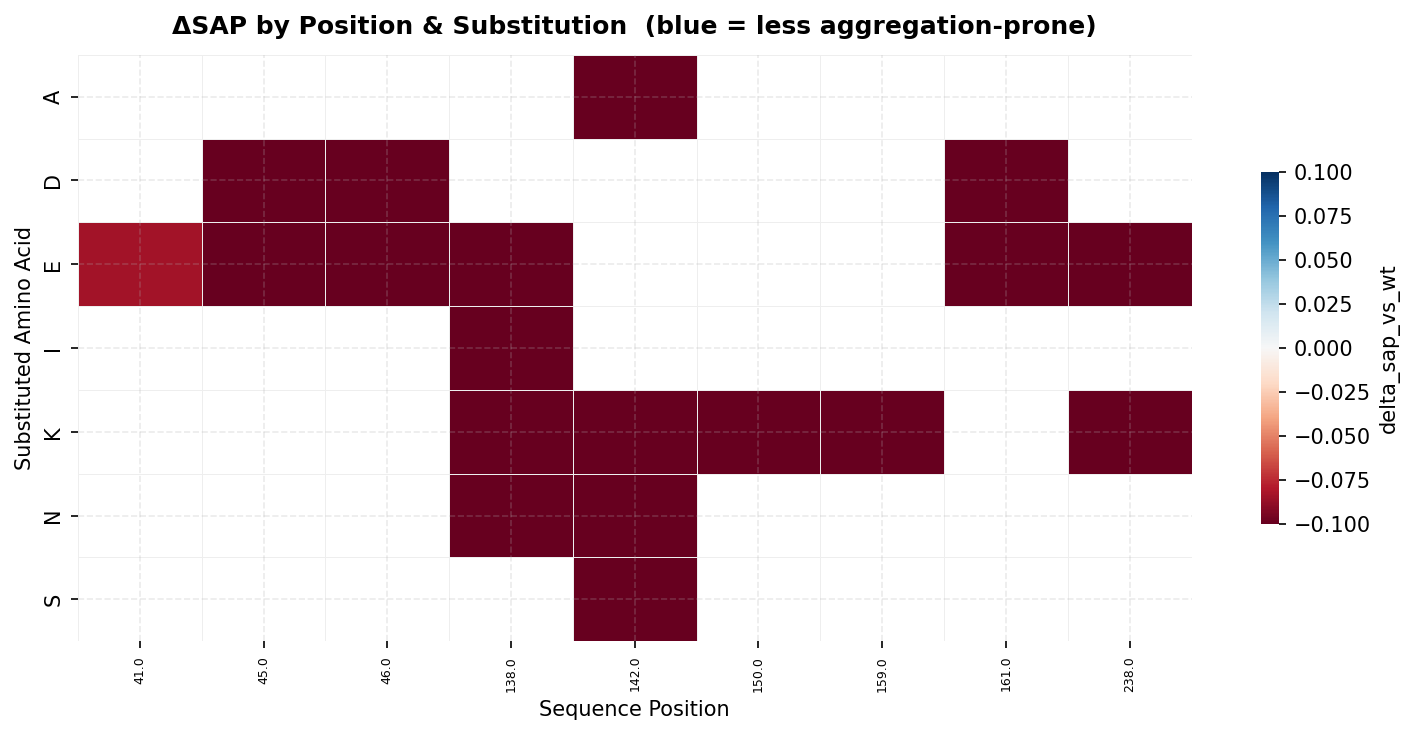

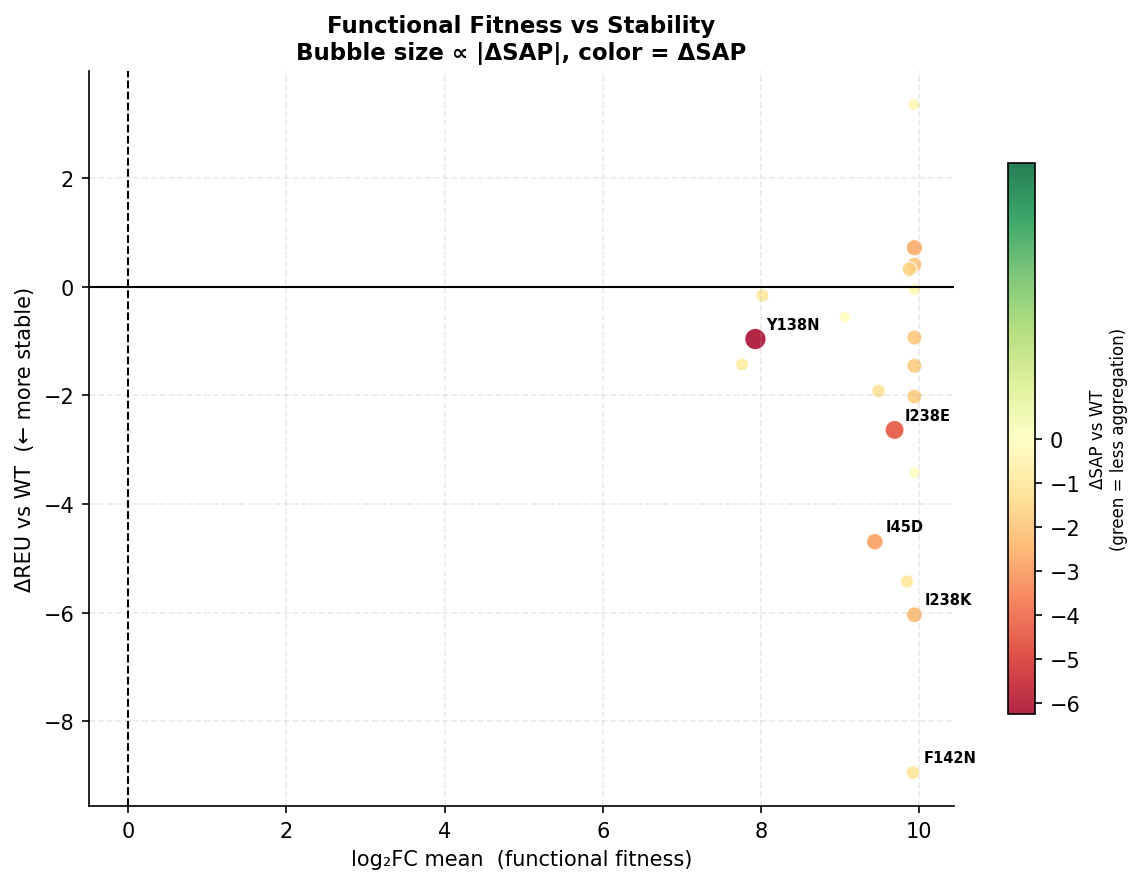

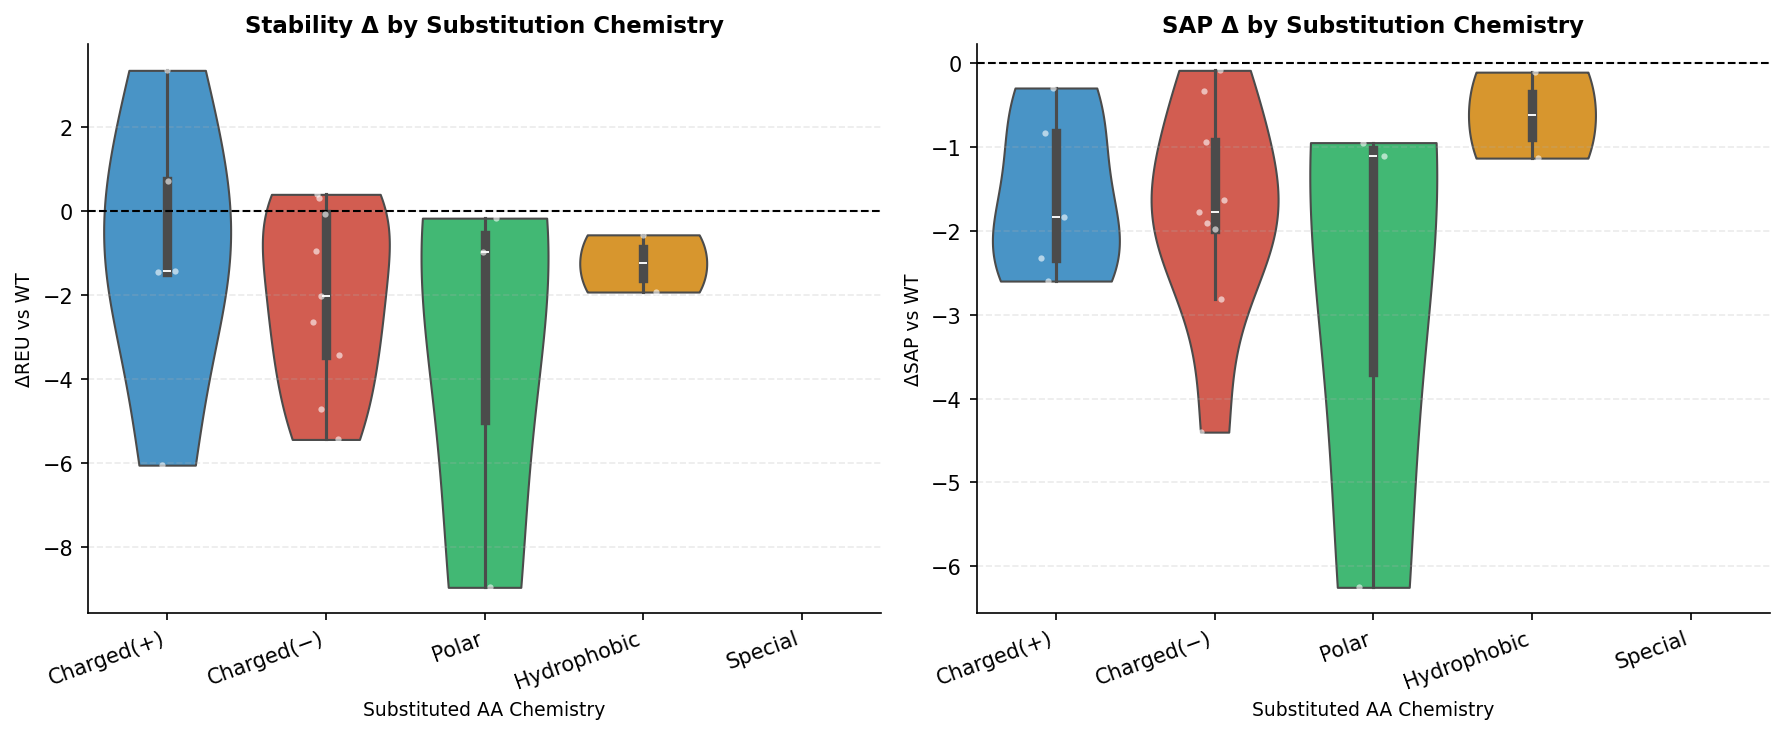

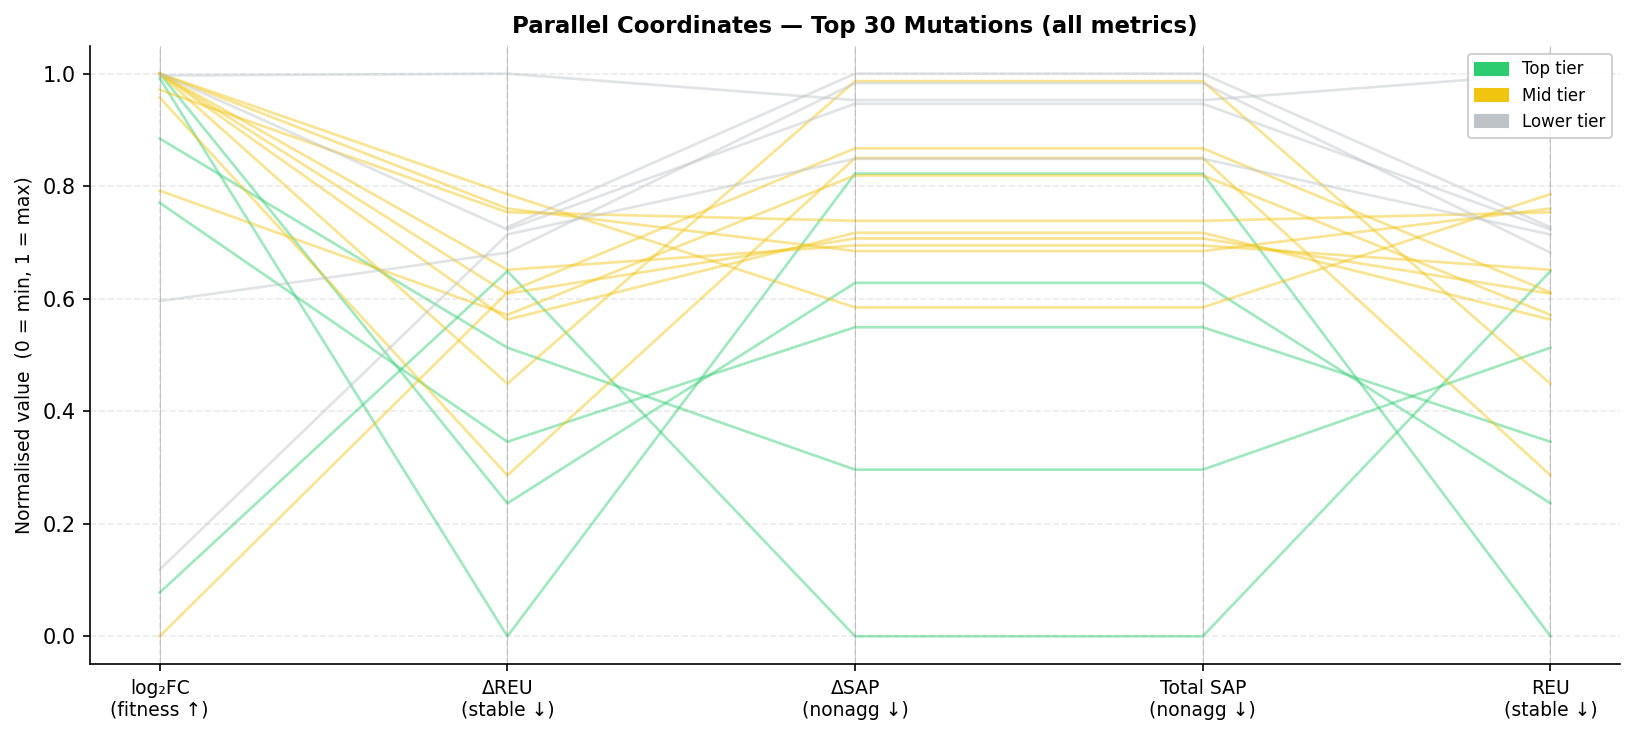


All figures saved to /home/llaage/projects/rh5_folding/260424_rh5_hydrophobics/scores/visualizations/


In [3]:
"""
Protein Surface Redesign — Mutation Data Visualizations
========================================================
Visualizes point mutation data from Rosetta-scored surface redesign:
  - delta_reu_vs_wt   : ΔΔG proxy; negative = more stable (GOOD)
  - delta_sap_vs_wt   : ΔSAP; negative = less aggregation-prone (GOOD)
  - log2fc_mean       : functional fitness from deep mutational scan / assay

Usage:
  pip install pandas matplotlib seaborn scipy
  python protein_mutation_viz.py

Set DATA_FILE to your CSV/TSV path, or use the synthetic demo data below.
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats

# ── 0. STYLE ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "figure.dpi": 150,
})

PALETTE = {
    "hit":      "#2ECC71",   # good on both axes  ✓
    "stable":   "#3498DB",   # better REU only
    "nonagg":   "#E67E22",   # better SAP only
    "neutral":  "#BDC3C7",   # worse on both
    "wt":       "#E74C3C",   # wildtype reference
    "accent":   "#8E44AD",
}

# ── 1. DATA ────────────────────────────────────────────────────────────────────
DATA_FILE = "/home/llaage/projects/rh5_folding/260424_rh5_hydrophobics/scores/mutation_ranking_matrix.csv"  # ← set to "your_data.csv" or "your_data.tsv"; None = demo

# ── Output directory ──────────────────────────────────────────────────────────
# Figures are saved into a "visualizations" folder next to DATA_FILE.
# When running in demo mode (DATA_FILE = None) the folder is created next to
# this script instead.
import os, pathlib
if DATA_FILE:
    OUT_DIR = pathlib.Path(DATA_FILE).parent / "visualizations"
else:
    OUT_DIR = pathlib.Path(__file__).parent / "visualizations"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def load_data(path):
    sep = "\t" if path.endswith(".tsv") else ","
    return pd.read_csv(path, sep=sep)

def make_demo_data(n=60, seed=42):
    """Synthetic dataset that mimics the real format."""
    rng = np.random.default_rng(seed)
    aa1 = list("ACDEFGHIKLMNPQRSTVWY")
    aa2 = list("ACDEFGHIKLMNPQRSTVWY")
    positions = rng.integers(1, 200, n)
    wt_aa  = rng.choice(aa1, n)
    mut_aa = rng.choice(aa2, n)
    mutations = [f"{w}{p}{m}" for w, p, m in zip(wt_aa, positions, mut_aa)]

    delta_reu = rng.normal(-3, 6, n)          # centered slightly beneficial
    delta_sap = rng.normal(-2, 5, n)          # centered slightly beneficial
    log2fc    = rng.normal(0.5, 1.5, n)       # mostly functional

    base_reu  = -510 + delta_reu + rng.normal(0, 2, n)
    base_sap  = 170  + delta_sap + rng.normal(0, 1, n)

    return pd.DataFrame({
        "input_pdb":       [f"MDL97_refine_{i:03d}.pdb" for i in rng.integers(1, 20, n)],
        "double_mutant":   double_mutation,
        "mutation":        mutations,
        "log2fc_mean":     log2fc,
        "total_sap":       base_sap,
        "REU":             base_reu,
        "delta_sap_vs_wt": delta_sap,
        "delta_reu_vs_wt": delta_reu,
    })

df = load_data(DATA_FILE) if DATA_FILE else make_demo_data()

# ── Derived columns ────────────────────────────────────────────────────────────
def parse_position(mut_str):
    m = re.search(r'\d+', str(mut_str))
    return int(m.group()) if m else np.nan

def parse_mut_aa(mut_str):
    return str(mut_str)[-1] if len(str(mut_str)) >= 2 else "?"

df["position"]    = df["mutation"].apply(parse_position)
df["mut_aa"]      = df["mutation"].apply(parse_mut_aa)
df["wt_aa"]       = df["mutation"].apply(lambda x: str(x)[0] if len(str(x)) >= 2 else "?")

# Quadrant classification
def classify(row):
    if row["delta_reu_vs_wt"] < 0 and row["delta_sap_vs_wt"] < 0:
        return "hit"
    elif row["delta_reu_vs_wt"] < 0:
        return "stable"
    elif row["delta_sap_vs_wt"] < 0:
        return "nonagg"
    return "neutral"

df["class"] = df.apply(classify, axis=1)

# Combined score (z-score sum; lower = better for both)
df["z_reu"] = (df["delta_reu_vs_wt"] - df["delta_reu_vs_wt"].mean()) / df["delta_reu_vs_wt"].std()
df["z_sap"] = (df["delta_sap_vs_wt"] - df["delta_sap_vs_wt"].mean()) / df["delta_sap_vs_wt"].std()
df["combined_score"] = df["z_reu"] + df["z_sap"]   # more negative = better

# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 1 — Quadrant scatter: ΔREU vs ΔSAP  (the hero plot)
# ═══════════════════════════════════════════════════════════════════════════════
fig1, ax = plt.subplots(figsize=(8, 7))

colors = df["class"].map(PALETTE)
sc = ax.scatter(
    df["delta_sap_vs_wt"], df["delta_reu_vs_wt"],
    c=colors, s=60 + 25 * df["log2fc_mean"].clip(-3, 3),
    edgecolors="white", linewidths=0.5, alpha=0.88, zorder=3
)

# Axes & quadrant lines
ax.axhline(0, color="black", lw=1.0, zorder=2)
ax.axvline(0, color="black", lw=1.0, zorder=2)

# Quadrant shading
ax.fill_between(
    [df["delta_sap_vs_wt"].min() - 1, 0],
    df["delta_reu_vs_wt"].min() - 1, 0,
    color=PALETTE["hit"], alpha=0.06
)

# Label top hits
hits = df[df["class"] == "hit"].nsmallest(6, "combined_score")
for _, row in hits.iterrows():
    ax.annotate(
        row["mutation"],
        xy=(row["delta_sap_vs_wt"], row["delta_reu_vs_wt"]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=7.5, color="#1A1A2E", fontweight="bold",
        arrowprops=dict(arrowstyle="-", color="grey", lw=0.7)
    )

# Quadrant labels
xlim, ylim = ax.get_xlim(), ax.get_ylim()
ax.text(xlim[0] + 0.5, ylim[0] + 0.5, "Less aggregation\nMore stable ★",
        fontsize=8, color=PALETTE["hit"], fontweight="bold", va="bottom")
ax.text(xlim[1] - 0.5, ylim[0] + 0.5, "More aggregation\nMore stable",
        fontsize=8, color=PALETTE["stable"], ha="right", va="bottom")
ax.text(xlim[0] + 0.5, ylim[1] - 0.5, "Less aggregation\nLess stable",
        fontsize=8, color=PALETTE["nonagg"], va="top")

legend_els = [
    mpatches.Patch(color=PALETTE["hit"],     label=f'Both improved (n={sum(df["class"]=="hit")})'),
    mpatches.Patch(color=PALETTE["stable"],  label=f'Stability only (n={sum(df["class"]=="stable")})'),
    mpatches.Patch(color=PALETTE["nonagg"],  label=f'SAP only (n={sum(df["class"]=="nonagg")})'),
    mpatches.Patch(color=PALETTE["neutral"], label=f'Neither (n={sum(df["class"]=="neutral")})'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='grey',
           markersize=6, label='Size ∝ log₂FC'),
]
ax.legend(handles=legend_els, fontsize=8, framealpha=0.9, loc="upper right")

ax.set_xlabel("ΔSAP vs WT", fontsize=10)
ax.set_ylabel("ΔREU vs WT", fontsize=10)
ax.set_title("Surface Redesign Mutations — Stability vs Surface Aggregation Propensity",
             fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
fig1.savefig(OUT_DIR / "fig1_quadrant_scatter.png", dpi=180, bbox_inches="tight")
print("Saved fig1_quadrant_scatter.png")


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 2 — Ranked lollipop: top mutations by combined score
# ═══════════════════════════════════════════════════════════════════════════════
TOP_N = 20
top = df.nsmallest(TOP_N, "combined_score").copy().reset_index(drop=True)
top = top.sort_values("combined_score")

fig2, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

for ax, col, label, direction in zip(
    axes,
    ["delta_reu_vs_wt", "delta_sap_vs_wt"],
    ["ΔREU vs WT (REU)", "ΔSAP vs WT"],
    ["↙ More stable", "↙ Less aggregation-prone"]
):
    colors_lol = [PALETTE["hit"] if v < 0 else PALETTE["neutral"] for v in top[col]]
    ax.hlines(top["mutation"], 0, top[col], color=colors_lol, linewidth=2, alpha=0.7)
    ax.scatter(top[col], top["mutation"], color=colors_lol, s=60, zorder=5)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel(f"{label}\n{direction}", fontsize=9)
    ax.tick_params(axis='y', labelsize=8)

axes[0].set_title(f"Top {TOP_N} mutations by combined ΔScore", fontsize=11, fontweight="bold")
plt.tight_layout()
fig2.savefig(OUT_DIR / "fig2_lollipop_top_hits.png", dpi=180, bbox_inches="tight")
print("Saved fig2_lollipop_top_hits.png")


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 3 — Sequence position heatmap
# ═══════════════════════════════════════════════════════════════════════════════
# Pivot: each position × mutant AA → value
def position_heatmap(df_in, value_col, title, cmap, center=0):
    piv = df_in.pivot_table(
        index="mut_aa", columns="position", values=value_col, aggfunc="mean"
    )
    fig, ax = plt.subplots(figsize=(max(10, len(piv.columns) * 0.35), 5))
    norm = TwoSlopeNorm(vmin=piv.values.min(), vcenter=center, vmax=piv.values.max())
    sns.heatmap(
        piv, ax=ax, cmap=cmap, norm=norm,
        linewidths=0.3, linecolor="#EEEEEE",
        cbar_kws={"label": value_col, "shrink": 0.6},
    )
    ax.set_xlabel("Sequence Position", fontsize=10)
    ax.set_ylabel("Substituted Amino Acid", fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.tick_params(axis="x", labelsize=6, rotation=90)
    plt.tight_layout()
    return fig

fig3a = position_heatmap(df, "delta_reu_vs_wt",
    "ΔREU by Position & Substitution  (blue = more stable)",
    "RdBu", center=0)
fig3a.savefig(OUT_DIR / "fig3a_heatmap_reu.png", dpi=180, bbox_inches="tight")

fig3b = position_heatmap(df, "delta_sap_vs_wt",
    "ΔSAP by Position & Substitution  (blue = less aggregation-prone)",
    "RdBu", center=0)
fig3b.savefig(OUT_DIR / "fig3b_heatmap_sap.png", dpi=180, bbox_inches="tight")
print("Saved fig3a/b heatmaps")


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 4 — Bubble plot: log2FC vs ΔREU, bubble size = |ΔSAP|
# ═══════════════════════════════════════════════════════════════════════════════
fig4, ax = plt.subplots(figsize=(8, 6))

bubble_size = 30 + 12 * np.abs(df["delta_sap_vs_wt"])
sap_min = min(df["delta_sap_vs_wt"].min(), -0.01)   # ensure vmin < 0
sap_max = max(df["delta_sap_vs_wt"].max(),  0.01)   # ensure vmax > 0
norm4 = TwoSlopeNorm(vmin=sap_min, vcenter=0, vmax=sap_max)
sc4 = ax.scatter(
    df["log2fc_mean"], df["delta_reu_vs_wt"],
    s=bubble_size, c=df["delta_sap_vs_wt"],
    cmap="RdYlGn", norm=norm4,
    edgecolors="white", linewidths=0.6, alpha=0.85
)
cbar = plt.colorbar(sc4, ax=ax, shrink=0.75)
cbar.set_label("ΔSAP vs WT\n(green = less aggregation)", fontsize=8)

ax.axhline(0, color="black", lw=1)
ax.axvline(0, color="black", lw=1, ls="--")

# Label top hits
for _, row in df[df["class"] == "hit"].nsmallest(5, "combined_score").iterrows():
    ax.annotate(row["mutation"],
                xy=(row["log2fc_mean"], row["delta_reu_vs_wt"]),
                xytext=(5, 5), textcoords="offset points",
                fontsize=7, fontweight="bold")

ax.set_xlabel("log₂FC mean  (functional fitness)", fontsize=10)
ax.set_ylabel("ΔREU vs WT  (← more stable)", fontsize=10)
ax.set_title("Functional Fitness vs Stability\nBubble size ∝ |ΔSAP|, color = ΔSAP",
             fontsize=11, fontweight="bold")
plt.tight_layout()
fig4.savefig(OUT_DIR / "fig4_bubble_log2fc_reu.png", dpi=180, bbox_inches="tight")
print("Saved fig4_bubble_log2fc_reu.png")


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 5 — AA chemistry class violin plots
# ═══════════════════════════════════════════════════════════════════════════════
# Group mutant AAs by physicochemical property
chem_class = {
    "Charged(+)":  list("KRH"),
    "Charged(−)":  list("DE"),
    "Polar":       list("STNQ"),
    "Hydrophobic": list("ACVILMFW"),
    "Special":     list("GPY"),
}
rev_map = {aa: grp for grp, aas in chem_class.items() for aa in aas}
df["chem_class"] = df["mut_aa"].map(rev_map).fillna("Other")

chem_order = ["Charged(+)", "Charged(−)", "Polar", "Hydrophobic", "Special"]
chem_palette = {
    "Charged(+)":  "#3498DB",
    "Charged(−)":  "#E74C3C",
    "Polar":       "#2ECC71",
    "Hydrophobic": "#F39C12",
    "Special":     "#9B59B6",
}

fig5, axes5 = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, label in zip(
    axes5,
    ["delta_reu_vs_wt", "delta_sap_vs_wt"],
    ["ΔREU vs WT", "ΔSAP vs WT"]
):
    sub = df[df["chem_class"].isin(chem_order)]
    sns.violinplot(
        data=sub, x="chem_class", y=col, order=chem_order,
        palette=chem_palette, inner="box", cut=0, ax=ax, linewidth=1
    )
    sns.stripplot(
        data=sub, x="chem_class", y=col, order=chem_order,
        color="white", size=3, alpha=0.6, jitter=True, ax=ax
    )
    ax.axhline(0, color="black", lw=1, ls="--")
    ax.set_xlabel("Substituted AA Chemistry", fontsize=9)
    ax.set_ylabel(label, fontsize=9)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")

axes5[0].set_title("Stability Δ by Substitution Chemistry", fontsize=11, fontweight="bold")
axes5[1].set_title("SAP Δ by Substitution Chemistry", fontsize=11, fontweight="bold")
plt.tight_layout()
fig5.savefig(OUT_DIR / "fig5_violin_chem_class.png", dpi=180, bbox_inches="tight")
print("Saved fig5_violin_chem_class.png")


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 6 — Parallel coordinates for multi-metric overview of top hits
# ═══════════════════════════════════════════════════════════════════════════════
top30 = df.nsmallest(30, "combined_score").copy().reset_index(drop=True)
top30["Rank"] = pd.cut(
    top30["combined_score"], bins=3,
    labels=["Top tier", "Mid tier", "Lower tier"]
)

pc_cols = ["log2fc_mean", "delta_reu_vs_wt", "delta_sap_vs_wt", "total_sap", "REU"]
pc_labels = [
    "log₂FC\n(fitness ↑)",
    "ΔREU\n(stable ↓)",
    "ΔSAP\n(nonagg ↓)",
    "Total SAP\n(nonagg ↓)",
    "REU\n(stable ↓)",
]
palette_pc = {"Top tier": PALETTE["hit"], "Mid tier": "#F1C40F", "Lower tier": PALETTE["neutral"]}

# Normalize each column to [0,1]
pc_norm = top30[pc_cols].copy()
for c in pc_cols:
    mn, mx = pc_norm[c].min(), pc_norm[c].max()
    pc_norm[c] = (pc_norm[c] - mn) / (mx - mn) if mx > mn else 0.5

fig6, ax = plt.subplots(figsize=(11, 5))
x_positions = np.arange(len(pc_cols))

for _, row in top30.iterrows():
    color = palette_pc[str(row["Rank"])]
    y_vals = [pc_norm.loc[row.name, c] for c in pc_cols]
    ax.plot(x_positions, y_vals, color=color, alpha=0.45, linewidth=1.3)

ax.set_xticks(x_positions)
ax.set_xticklabels(pc_labels, fontsize=9)
ax.set_ylabel("Normalised value  (0 = min, 1 = max)", fontsize=9)
ax.set_title("Parallel Coordinates — Top 30 Mutations (all metrics)",
             fontsize=11, fontweight="bold")
ax.set_ylim(-0.05, 1.05)
ax.grid(axis="x", linestyle="--", alpha=0.3)

handles = [mpatches.Patch(color=v, label=k) for k, v in palette_pc.items()]
ax.legend(handles=handles, fontsize=8, framealpha=0.9, loc="upper right")

# Vertical axis lines
for xp in x_positions:
    ax.axvline(xp, color="grey", lw=0.5, alpha=0.4)

plt.tight_layout()
fig6.savefig(OUT_DIR / "fig6_parallel_coordinates.png", dpi=180, bbox_inches="tight")
print("Saved fig6_parallel_coordinates.png")

plt.show()
print(f"\nAll figures saved to {OUT_DIR}/")

No single-mutant 'mutation' rows found — skipping single-mutant figures.

── Double-mutant figures ──────────────────────────────────────────
Skipping fig7_epistasis_scatter.png: no double mutants had matching singles.
Saved fig8a_pairpos_reu.png
Saved fig8b_pairpos_sap.png
Skipping fig9_single_vs_double_violin.png: no singles to compare.
Saved fig10_double_top_hits.png
  → 269 double mutants processed; 0 had matching singles for epistasis analysis.


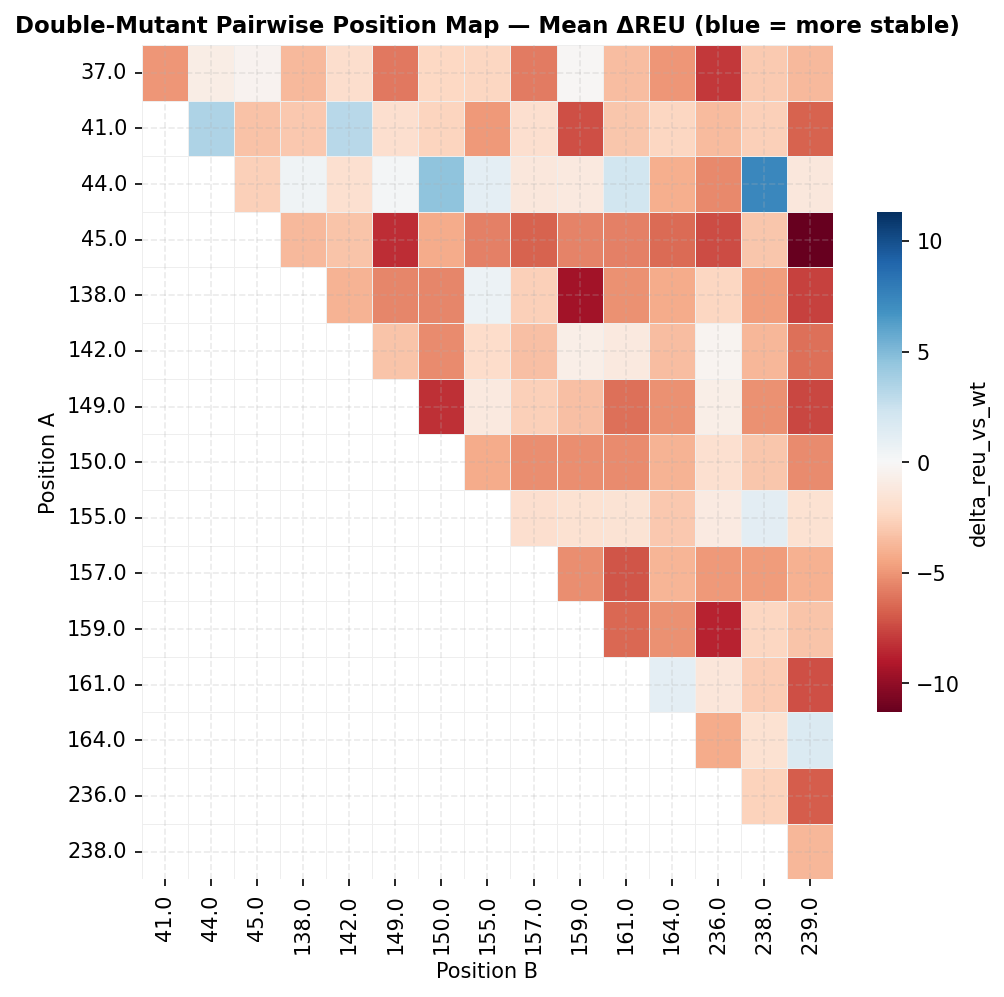

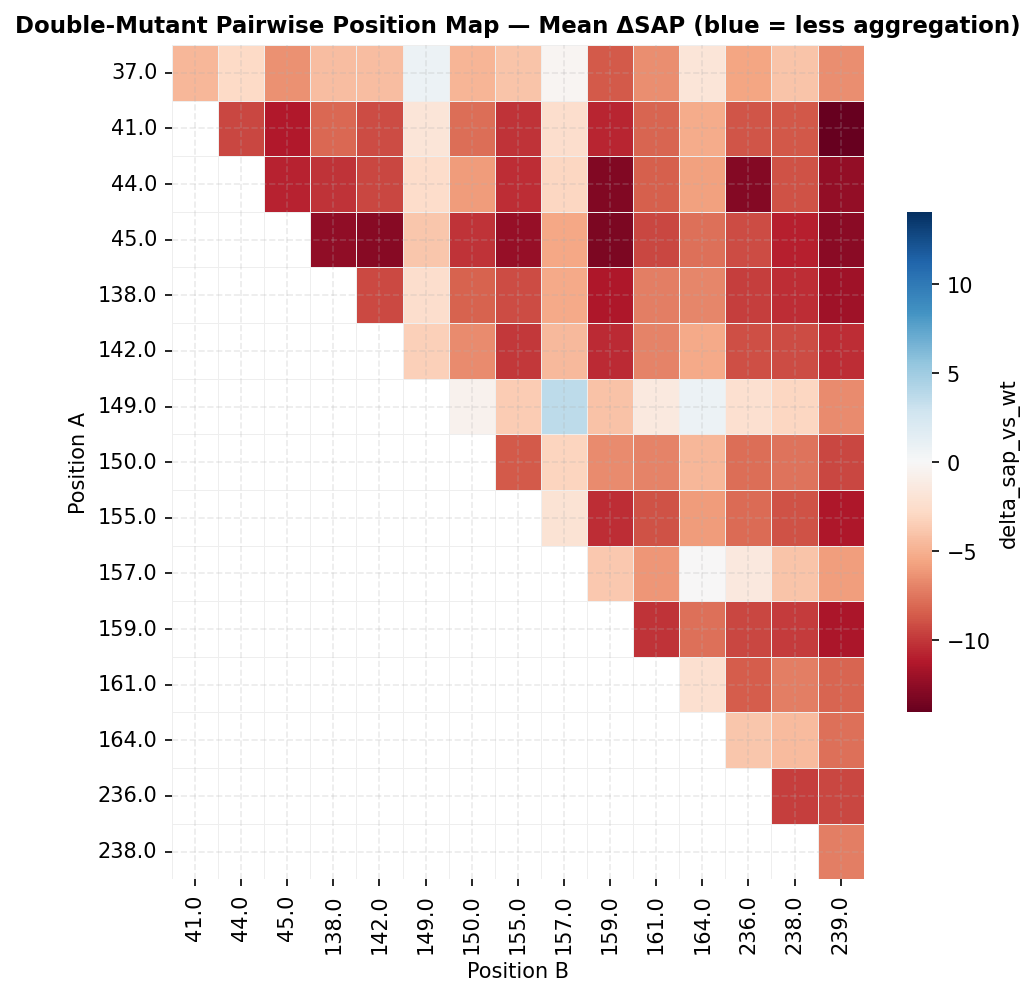

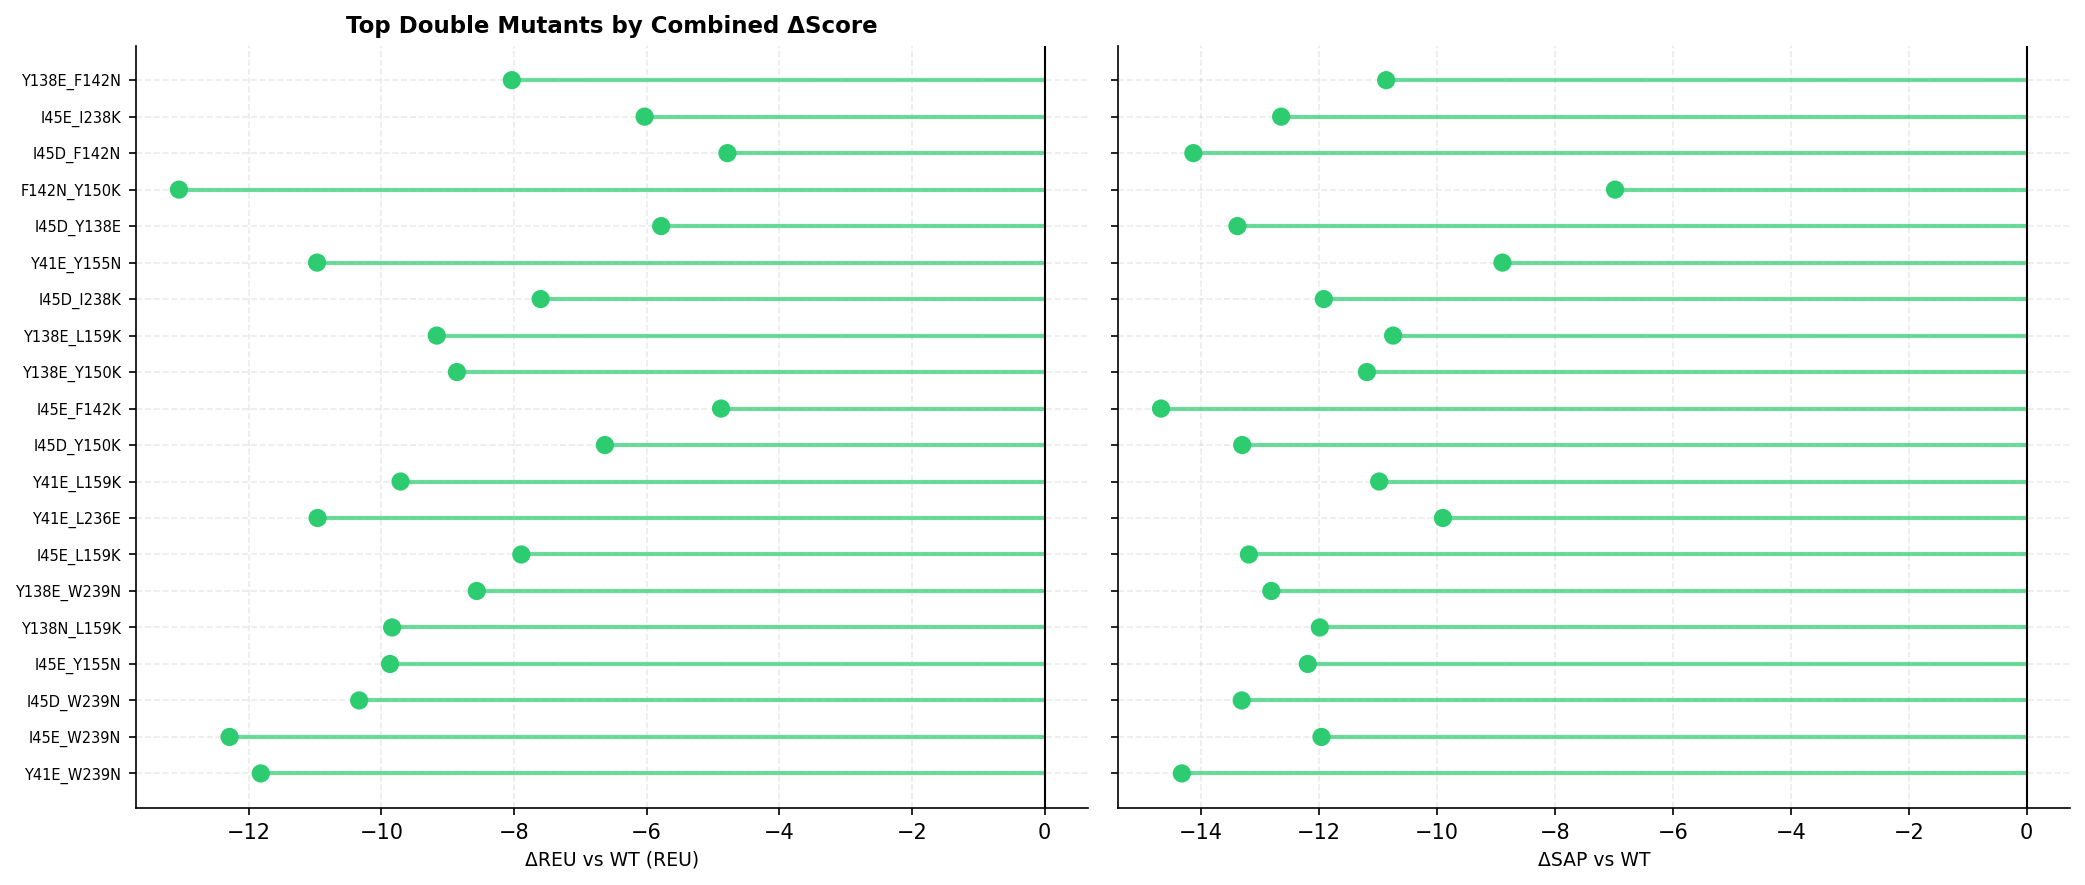


All figures saved to /home/llaage/projects/rh5_folding/260511_double_mut/scores/visualizations/


In [4]:
"""
Protein Surface Redesign — Mutation Data Visualizations
========================================================
Visualizes point mutation data from Rosetta-scored surface redesign:
  - delta_reu_vs_wt   : ΔΔG proxy; negative = more stable (GOOD)
  - delta_sap_vs_wt   : ΔSAP; negative = less aggregation-prone (GOOD)
  - log2fc_mean       : functional fitness from deep mutational scan / assay

Usage:
  pip install pandas matplotlib seaborn scipy
  python protein_mutation_viz_fixed.py

Set DATA_FILE to your CSV/TSV path, or set it to None to use synthetic demo data.
"""

import pathlib
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats

# ── 0. STYLE ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "figure.dpi": 150,
})

PALETTE = {
    "hit":      "#2ECC71",   # good on both axes ✓
    "stable":   "#3498DB",   # better REU only
    "nonagg":   "#E67E22",   # better SAP only
    "neutral":  "#BDC3C7",   # worse on both
    "wt":       "#E74C3C",   # wildtype reference
    "accent":   "#8E44AD",
}

# ── 1. DATA ───────────────────────────────────────────────────────────────────
# Change this to your own CSV/TSV path. Set to None for demo data.
DATA_FILE = "/home/llaage/projects/rh5_folding/260511_double_mut/scores/mutation_ranking_matrix.csv"

# Required input columns for the main plots.
REQUIRED_METRIC_COLS = [
    "delta_reu_vs_wt",
    "delta_sap_vs_wt",
    "total_sap",
    "REU",
]


def load_data(path):
    sep = "\t" if str(path).endswith(".tsv") else ","
    return pd.read_csv(path, sep=sep)


def make_demo_data(n=60, seed=42):
    """Synthetic dataset that mimics the real format."""
    rng = np.random.default_rng(seed)
    aa1 = list("ACDEFGHIKLMNPQRSTVWY")
    aa2 = list("ACDEFGHIKLMNPQRSTVWY")
    positions = rng.integers(1, 200, n)
    wt_aa = rng.choice(aa1, n)
    mut_aa = rng.choice(aa2, n)
    mutations = [f"{w}{p}{m}" for w, p, m in zip(wt_aa, positions, mut_aa)]

    delta_reu = rng.normal(-3, 6, n)
    delta_sap = rng.normal(-2, 5, n)
    log2fc = rng.normal(0.5, 1.5, n)

    base_reu = -510 + delta_reu + rng.normal(0, 2, n)
    base_sap = 170 + delta_sap + rng.normal(0, 1, n)

    singles = pd.DataFrame({
        "input_pdb":       [f"MDL97_refine_{i:03d}.pdb" for i in rng.integers(1, 20, n)],
        "mutation":        mutations,
        "double_mutant":   np.nan,
        "log2fc_mean":     log2fc,
        "total_sap":       base_sap,
        "REU":             base_reu,
        "delta_sap_vs_wt": delta_sap,
        "delta_reu_vs_wt": delta_reu,
    })

    nd = 30
    idx_a = rng.choice(n, nd, replace=True)
    idx_b = rng.choice(n, nd, replace=True)
    mask = idx_a != idx_b
    idx_a, idx_b = idx_a[mask], idx_b[mask]

    epistasis_reu = rng.normal(0, 2, len(idx_a))
    epistasis_sap = rng.normal(0, 1.5, len(idx_a))
    dm_delta_reu = delta_reu[idx_a] + delta_reu[idx_b] + epistasis_reu
    dm_delta_sap = delta_sap[idx_a] + delta_sap[idx_b] + epistasis_sap

    doubles = pd.DataFrame({
        "input_pdb":       [f"MDL97_refine_{i:03d}.pdb" for i in rng.integers(1, 20, len(idx_a))],
        "mutation":        np.nan,
        "double_mutant":   [f"{mutations[a]}_{mutations[b]}" for a, b in zip(idx_a, idx_b)],
        "total_sap":       170 + dm_delta_sap + rng.normal(0, 1, len(idx_a)),
        "REU":             -510 + dm_delta_reu + rng.normal(0, 2, len(idx_a)),
        "delta_sap_vs_wt": dm_delta_sap,
        "delta_reu_vs_wt": dm_delta_reu,
    })

    return pd.concat([singles, doubles], ignore_index=True)


def parse_position(mut_str):
    m = re.search(r"\d+", str(mut_str))
    return int(m.group()) if m else np.nan


def parse_mut_aa(mut_str):
    s = str(mut_str)
    return s[-1] if len(s) >= 2 and s.lower() != "nan" else "?"


def parse_wt_aa(mut_str):
    s = str(mut_str)
    return s[0] if len(s) >= 2 and s.lower() != "nan" else "?"


def classify(row):
    """Quadrant classification: negative REU and negative SAP are both good."""
    if row["delta_reu_vs_wt"] < 0 and row["delta_sap_vs_wt"] < 0:
        return "hit"
    if row["delta_reu_vs_wt"] < 0:
        return "stable"
    if row["delta_sap_vs_wt"] < 0:
        return "nonagg"
    return "neutral"


def safe_zscore(series):
    """Return z-scores; avoid division by zero when all values are identical."""
    std = series.std()
    if pd.isna(std) or std == 0:
        return pd.Series(0.0, index=series.index)
    return (series - series.mean()) / std


def add_derived_columns(df_in, mutation_col="mutation"):
    """Add class, z-scores, combined_score, and mutation parsing columns."""
    df_out = df_in.copy()

    df_out["class"] = df_out.apply(classify, axis=1)
    df_out["z_reu"] = safe_zscore(df_out["delta_reu_vs_wt"])
    df_out["z_sap"] = safe_zscore(df_out["delta_sap_vs_wt"])
    df_out["combined_score"] = df_out["z_reu"] + df_out["z_sap"]

    if mutation_col in df_out.columns:
        df_out["position"] = df_out[mutation_col].apply(parse_position)
        df_out["mut_aa"] = df_out[mutation_col].apply(parse_mut_aa)
        df_out["wt_aa"] = df_out[mutation_col].apply(parse_wt_aa)

    return df_out


def safe_twoslope_norm(values, center=0.0, pad=1e-9):
    """Build a TwoSlopeNorm without crashing on constant or one-sided values."""
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]

    if arr.size == 0:
        return TwoSlopeNorm(vmin=center - 1, vcenter=center, vmax=center + 1)

    vmin = float(np.nanmin(arr))
    vmax = float(np.nanmax(arr))

    # TwoSlopeNorm requires vmin < vcenter < vmax.
    if vmin >= center:
        vmin = center - max(abs(vmax - center), 1.0) - pad
    if vmax <= center:
        vmax = center + max(abs(center - vmin), 1.0) + pad
    if vmin == vmax:
        vmin -= 1.0
        vmax += 1.0

    return TwoSlopeNorm(vmin=vmin, vcenter=center, vmax=vmax)


def safe_point_sizes(values, base=60, scale=25, clip_min=-3, clip_max=3, min_size=10):
    """Matplotlib scatter sizes must be non-negative."""
    sizes = base + scale * values.clip(clip_min, clip_max)
    return sizes.clip(lower=min_size)


def split_double(dm_str):
    """Split 'A46E_G102D' or 'A46E/G102D' into ('A46E', 'G102D')."""
    s = str(dm_str)
    sep = "_" if "_" in s else "/"
    parts = [p.strip() for p in s.split(sep) if p.strip()]

    if len(parts) >= 2:
        return parts[0], parts[1]
    if len(parts) == 1:
        return parts[0], ""
    return "", ""


def require_columns(df_in, cols):
    missing = [c for c in cols if c not in df_in.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {missing}")


def position_heatmap(df_in, value_col, title, cmap, center=0):
    piv = df_in.pivot_table(
        index="mut_aa",
        columns="position",
        values=value_col,
        aggfunc="mean",
    )

    if piv.empty:
        print(f"Skipping heatmap for {value_col}: no pivotable data.")
        return None

    fig, ax = plt.subplots(figsize=(max(10, len(piv.columns) * 0.35), 5))
    norm = safe_twoslope_norm(piv.values, center=center)

    sns.heatmap(
        piv,
        ax=ax,
        cmap=cmap,
        norm=norm,
        linewidths=0.3,
        linecolor="#EEEEEE",
        cbar_kws={"label": value_col, "shrink": 0.6},
    )

    ax.set_xlabel("Sequence Position", fontsize=10)
    ax.set_ylabel("Substituted Amino Acid", fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.tick_params(axis="x", labelsize=6, rotation=90)
    plt.tight_layout()

    return fig


def main():
    if DATA_FILE:
        out_dir = pathlib.Path(DATA_FILE).parent / "visualizations"
    else:
        out_dir = pathlib.Path(__file__).parent / "visualizations"

    out_dir.mkdir(parents=True, exist_ok=True)

    df_all = load_data(DATA_FILE) if DATA_FILE else make_demo_data()
    require_columns(df_all, REQUIRED_METRIC_COLS)

    # ── Split into single-mutant and double-mutant subsets ────────────────────
    has_doubles = (
        "double_mutant" in df_all.columns
        and df_all["double_mutant"].notna().any()
    )

    if has_doubles:
        df_s = df_all[df_all["double_mutant"].isna()].copy().reset_index(drop=True)
        df_d = df_all[df_all["double_mutant"].notna()].copy().reset_index(drop=True)
    else:
        df_s = df_all.copy().reset_index(drop=True)
        df_d = pd.DataFrame()

    has_singles = "mutation" in df_s.columns and df_s["mutation"].notna().any()

    if not has_singles:
        print("No single-mutant 'mutation' rows found — skipping single-mutant figures.")
    else:
        df = add_derived_columns(df_s, mutation_col="mutation")

        # ═══════════════════════════════════════════════════════════════════════
        # FIGURE 1 — Quadrant scatter: ΔREU vs ΔSAP
        # ═══════════════════════════════════════════════════════════════════════
        fig1, ax = plt.subplots(figsize=(8, 7))

        colors = df["class"].map(PALETTE)

        ax.scatter(
            df["delta_sap_vs_wt"],
            df["delta_reu_vs_wt"],
            c=colors,
            s=safe_point_sizes(df["log2fc_mean"]),
            edgecolors="white",
            linewidths=0.5,
            alpha=0.88,
            zorder=3,
        )

        ax.axhline(0, color="black", lw=1.0, zorder=2)
        ax.axvline(0, color="black", lw=1.0, zorder=2)

        ax.fill_between(
            [df["delta_sap_vs_wt"].min() - 1, 0],
            df["delta_reu_vs_wt"].min() - 1,
            0,
            color=PALETTE["hit"],
            alpha=0.06,
        )

        hits = df[df["class"] == "hit"].nsmallest(6, "combined_score")

        for _, row in hits.iterrows():
            ax.annotate(
                row["mutation"],
                xy=(row["delta_sap_vs_wt"], row["delta_reu_vs_wt"]),
                xytext=(6, 6),
                textcoords="offset points",
                fontsize=7.5,
                color="#1A1A2E",
                fontweight="bold",
                arrowprops=dict(arrowstyle="-", color="grey", lw=0.7),
            )

        xlim, ylim = ax.get_xlim(), ax.get_ylim()

        ax.text(
            xlim[0] + 0.5,
            ylim[0] + 0.5,
            "Less aggregation\nMore stable ★",
            fontsize=8,
            color=PALETTE["hit"],
            fontweight="bold",
            va="bottom",
        )

        ax.text(
            xlim[1] - 0.5,
            ylim[0] + 0.5,
            "More aggregation\nMore stable",
            fontsize=8,
            color=PALETTE["stable"],
            ha="right",
            va="bottom",
        )

        ax.text(
            xlim[0] + 0.5,
            ylim[1] - 0.5,
            "Less aggregation\nLess stable",
            fontsize=8,
            color=PALETTE["nonagg"],
            va="top",
        )

        legend_els = [
            mpatches.Patch(
                color=PALETTE["hit"],
                label=f'Both improved (n={sum(df["class"] == "hit")})',
            ),
            mpatches.Patch(
                color=PALETTE["stable"],
                label=f'Stability only (n={sum(df["class"] == "stable")})',
            ),
            mpatches.Patch(
                color=PALETTE["nonagg"],
                label=f'SAP only (n={sum(df["class"] == "nonagg")})',
            ),
            mpatches.Patch(
                color=PALETTE["neutral"],
                label=f'Neither (n={sum(df["class"] == "neutral")})',
            ),
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                markerfacecolor="grey",
                markersize=6,
                label="Size ∝ log₂FC",
            ),
        ]

        ax.legend(handles=legend_els, fontsize=8, framealpha=0.9, loc="upper right")

        ax.set_xlabel("ΔSAP vs WT  (← better: less aggregation-prone)", fontsize=10)
        ax.set_ylabel("ΔREU vs WT  (← better: more stable)", fontsize=10)
        ax.set_title(
            "Surface Redesign Mutations — Stability vs Aggregation Propensity",
            fontsize=12,
            fontweight="bold",
            pad=12,
        )

        plt.tight_layout()
        fig1.savefig(out_dir / "fig1_quadrant_scatter.png", dpi=180, bbox_inches="tight")
        print("Saved fig1_quadrant_scatter.png")

        # ═══════════════════════════════════════════════════════════════════════
        # FIGURE 2 — Ranked lollipop: top mutations by combined score
        # ═══════════════════════════════════════════════════════════════════════
        top_n = min(20, len(df))
        top = df.nsmallest(top_n, "combined_score").copy().reset_index(drop=True)
        top = top.sort_values("combined_score")

        fig2, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

        for ax, col, label, direction in zip(
            axes,
            ["delta_reu_vs_wt", "delta_sap_vs_wt"],
            ["ΔREU vs WT (REU)", "ΔSAP vs WT"],
            ["↙ More stable", "↙ Less aggregation-prone"],
        ):
            colors_lol = [
                PALETTE["hit"] if v < 0 else PALETTE["neutral"]
                for v in top[col]
            ]

            ax.hlines(
                top["mutation"],
                0,
                top[col],
                color=colors_lol,
                linewidth=2,
                alpha=0.7,
            )

            ax.scatter(
                top[col],
                top["mutation"],
                color=colors_lol,
                s=60,
                zorder=5,
            )

            ax.axvline(0, color="black", lw=1)
            ax.set_xlabel(f"{label}\n{direction}", fontsize=9)
            ax.tick_params(axis="y", labelsize=8)

        axes[0].set_title(
            f"Top {top_n} mutations by combined ΔScore",
            fontsize=11,
            fontweight="bold",
        )

        plt.tight_layout()
        fig2.savefig(out_dir / "fig2_lollipop_top_hits.png", dpi=180, bbox_inches="tight")
        print("Saved fig2_lollipop_top_hits.png")

        # ═══════════════════════════════════════════════════════════════════════
        # FIGURE 3 — Sequence position heatmap
        # ═══════════════════════════════════════════════════════════════════════
        fig3a = position_heatmap(
            df,
            "delta_reu_vs_wt",
            "ΔREU by Position & Substitution  (blue = more stable)",
            "RdBu",
            center=0,
        )

        if fig3a is not None:
            fig3a.savefig(out_dir / "fig3a_heatmap_reu.png", dpi=180, bbox_inches="tight")

        fig3b = position_heatmap(
            df,
            "delta_sap_vs_wt",
            "ΔSAP by Position & Substitution  (blue = less aggregation-prone)",
            "RdBu",
            center=0,
        )

        if fig3b is not None:
            fig3b.savefig(out_dir / "fig3b_heatmap_sap.png", dpi=180, bbox_inches="tight")

        print("Saved fig3a/b heatmaps")

        # ═══════════════════════════════════════════════════════════════════════
        # FIGURE 4 — Bubble plot: log2FC vs ΔREU, bubble size = |ΔSAP|
        # ═══════════════════════════════════════════════════════════════════════
        fig4, ax = plt.subplots(figsize=(8, 6))

        bubble_size = 30 + 12 * np.abs(df["delta_sap_vs_wt"])
        norm4 = safe_twoslope_norm(df["delta_sap_vs_wt"], center=0)

        sc4 = ax.scatter(
            df["log2fc_mean"],
            df["delta_reu_vs_wt"],
            s=bubble_size,
            c=df["delta_sap_vs_wt"],
            cmap="RdYlGn",
            norm=norm4,
            edgecolors="white",
            linewidths=0.6,
            alpha=0.85,
        )

        cbar = plt.colorbar(sc4, ax=ax, shrink=0.75)
        cbar.set_label("ΔSAP vs WT\n(green = less aggregation)", fontsize=8)

        ax.axhline(0, color="black", lw=1)
        ax.axvline(0, color="black", lw=1, ls="--")

        for _, row in df[df["class"] == "hit"].nsmallest(5, "combined_score").iterrows():
            ax.annotate(
                row["mutation"],
                xy=(row["log2fc_mean"], row["delta_reu_vs_wt"]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=7,
                fontweight="bold",
            )

        ax.set_xlabel("log₂FC mean  (functional fitness)", fontsize=10)
        ax.set_ylabel("ΔREU vs WT  (← more stable)", fontsize=10)
        ax.set_title(
            "Functional Fitness vs Stability\nBubble size ∝ |ΔSAP|, color = ΔSAP",
            fontsize=11,
            fontweight="bold",
        )

        plt.tight_layout()
        fig4.savefig(out_dir / "fig4_bubble_log2fc_reu.png", dpi=180, bbox_inches="tight")
        print("Saved fig4_bubble_log2fc_reu.png")

        # ═══════════════════════════════════════════════════════════════════════
        # FIGURE 5 — AA chemistry class violin plots
        # ═══════════════════════════════════════════════════════════════════════
        chem_class = {
            "Charged(+)":  list("KRH"),
            "Charged(−)":  list("DE"),
            "Polar":       list("STNQ"),
            "Hydrophobic": list("ACVILMFW"),
            "Special":     list("GPY"),
        }

        rev_map = {aa: grp for grp, aas in chem_class.items() for aa in aas}
        df["chem_class"] = df["mut_aa"].map(rev_map).fillna("Other")

        chem_order = [
            "Charged(+)",
            "Charged(−)",
            "Polar",
            "Hydrophobic",
            "Special",
        ]

        chem_palette = {
            "Charged(+)":  "#3498DB",
            "Charged(−)":  "#E74C3C",
            "Polar":       "#2ECC71",
            "Hydrophobic": "#F39C12",
            "Special":     "#9B59B6",
        }

        fig5, axes5 = plt.subplots(1, 2, figsize=(12, 5))

        for ax, col, label in zip(
            axes5,
            ["delta_reu_vs_wt", "delta_sap_vs_wt"],
            ["ΔREU vs WT", "ΔSAP vs WT"],
        ):
            sub = df[df["chem_class"].isin(chem_order)]

            sns.violinplot(
                data=sub,
                x="chem_class",
                y=col,
                order=chem_order,
                palette=chem_palette,
                inner="box",
                cut=0,
                ax=ax,
                linewidth=1,
                hue="chem_class",
                legend=False,
            )

            sns.stripplot(
                data=sub,
                x="chem_class",
                y=col,
                order=chem_order,
                color="white",
                size=3,
                alpha=0.6,
                jitter=True,
                ax=ax,
            )

            ax.axhline(0, color="black", lw=1, ls="--")
            ax.set_xlabel("Substituted AA Chemistry", fontsize=9)
            ax.set_ylabel(label, fontsize=9)
            ax.set_xticks(ax.get_xticks())
            ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")

        axes5[0].set_title(
            "Stability Δ by Substitution Chemistry",
            fontsize=11,
            fontweight="bold",
        )

        axes5[1].set_title(
            "SAP Δ by Substitution Chemistry",
            fontsize=11,
            fontweight="bold",
        )

        plt.tight_layout()
        fig5.savefig(out_dir / "fig5_violin_chem_class.png", dpi=180, bbox_inches="tight")
        print("Saved fig5_violin_chem_class.png")

        # ═══════════════════════════════════════════════════════════════════════
        # FIGURE 6 — Parallel coordinates for multi-metric overview of top hits
        # ═══════════════════════════════════════════════════════════════════════
        top30 = df.nsmallest(min(30, len(df)), "combined_score").copy().reset_index(drop=True)

        if len(top30) >= 3:
            top30["Rank"] = pd.cut(
                top30["combined_score"],
                bins=3,
                labels=["Top tier", "Mid tier", "Lower tier"],
                duplicates="drop",
            )
        else:
            top30["Rank"] = "Top tier"

        pc_cols = [
            "log2fc_mean",
            "delta_reu_vs_wt",
            "delta_sap_vs_wt",
            "total_sap",
            "REU",
        ]

        pc_labels = [
            "log₂FC\n(fitness ↑)",
            "ΔREU\n(stable ↓)",
            "ΔSAP\n(nonagg ↓)",
            "Total SAP\n(nonagg ↓)",
            "REU\n(stable ↓)",
        ]

        palette_pc = {
            "Top tier": PALETTE["hit"],
            "Mid tier": "#F1C40F",
            "Lower tier": PALETTE["neutral"],
        }

        pc_norm = top30[pc_cols].copy()

        for c in pc_cols:
            mn, mx = pc_norm[c].min(), pc_norm[c].max()
            pc_norm[c] = (pc_norm[c] - mn) / (mx - mn) if mx > mn else 0.5

        fig6, ax = plt.subplots(figsize=(11, 5))
        x_positions = np.arange(len(pc_cols))

        for _, row in top30.iterrows():
            rank = str(row["Rank"])
            color = palette_pc.get(rank, PALETTE["neutral"])
            y_vals = [pc_norm.loc[row.name, c] for c in pc_cols]
            ax.plot(x_positions, y_vals, color=color, alpha=0.45, linewidth=1.3)

        ax.set_xticks(x_positions)
        ax.set_xticklabels(pc_labels, fontsize=9)
        ax.set_ylabel("Normalised value  (0 = min, 1 = max)", fontsize=9)
        ax.set_title(
            "Parallel Coordinates — Top 30 Mutations (all metrics)",
            fontsize=11,
            fontweight="bold",
        )

        ax.set_ylim(-0.05, 1.05)
        ax.grid(axis="x", linestyle="--", alpha=0.3)

        present_ranks = [r for r in palette_pc if r in set(top30["Rank"].astype(str))]
        handles = [mpatches.Patch(color=palette_pc[r], label=r) for r in present_ranks]

        if handles:
            ax.legend(handles=handles, fontsize=8, framealpha=0.9, loc="upper right")

        for xp in x_positions:
            ax.axvline(xp, color="grey", lw=0.5, alpha=0.4)

        plt.tight_layout()
        fig6.savefig(out_dir / "fig6_parallel_coordinates.png", dpi=180, bbox_inches="tight")
        print("Saved fig6_parallel_coordinates.png")

    # ═══════════════════════════════════════════════════════════════════════════
    # DOUBLE-MUTANT FIGURES
    # ═══════════════════════════════════════════════════════════════════════════
    if has_doubles:
        print("\n── Double-mutant figures ──────────────────────────────────────────")

        df_d = add_derived_columns(df_d, mutation_col="double_mutant")

        df_d[["mut_a", "mut_b"]] = pd.DataFrame(
            df_d["double_mutant"].apply(split_double).tolist(),
            index=df_d.index,
        )

        df_d["pos_a"] = df_d["mut_a"].apply(parse_position)
        df_d["pos_b"] = df_d["mut_b"].apply(parse_position)

        if has_singles:
            s_lookup = (
                df_s
                .dropna(subset=["mutation"])
                .set_index("mutation")[["delta_reu_vs_wt", "delta_sap_vs_wt"]]
            )
        else:
            s_lookup = pd.DataFrame(columns=["delta_reu_vs_wt", "delta_sap_vs_wt"])

        def additive_expected(row, col):
            a = s_lookup.at[row["mut_a"], col] if row["mut_a"] in s_lookup.index else np.nan
            b = s_lookup.at[row["mut_b"], col] if row["mut_b"] in s_lookup.index else np.nan
            return a + b if pd.notna(a) and pd.notna(b) else np.nan

        df_d["exp_reu"] = df_d.apply(
            lambda r: additive_expected(r, "delta_reu_vs_wt"),
            axis=1,
        )

        df_d["exp_sap"] = df_d.apply(
            lambda r: additive_expected(r, "delta_sap_vs_wt"),
            axis=1,
        )

        df_d["epistasis_reu"] = df_d["delta_reu_vs_wt"] - df_d["exp_reu"]
        df_d["epistasis_sap"] = df_d["delta_sap_vs_wt"] - df_d["exp_sap"]

        # ── FIG 7 — Epistasis scatter: observed vs additive expected ─────────
        df_ep = df_d.dropna(subset=["exp_reu", "exp_sap"]).copy()

        if not df_ep.empty:
            fig7, axes7 = plt.subplots(1, 2, figsize=(12, 5))

            for ax, obs_col, exp_col, label in zip(
                axes7,
                ["delta_reu_vs_wt", "delta_sap_vs_wt"],
                ["exp_reu", "exp_sap"],
                ["ΔREU (REU)", "ΔSAP"],
            ):
                epi_col = "epistasis_reu" if "reu" in exp_col else "epistasis_sap"
                ep_vals = df_ep[epi_col]
                norm_ep = safe_twoslope_norm(ep_vals, center=0)

                sc = ax.scatter(
                    df_ep[exp_col],
                    df_ep[obs_col],
                    c=ep_vals,
                    cmap="RdYlGn_r",
                    norm=norm_ep,
                    s=60,
                    edgecolors="white",
                    linewidths=0.5,
                    alpha=0.85,
                    zorder=3,
                )

                plt.colorbar(
                    sc,
                    ax=ax,
                    shrink=0.75,
                    label="Epistasis (obs - additive) / red = neg. epistasis",
                )

                lims = [
                    min(df_ep[exp_col].min(), df_ep[obs_col].min()) - 1,
                    max(df_ep[exp_col].max(), df_ep[obs_col].max()) + 1,
                ]

                ax.plot(lims, lims, "k--", lw=1, label="Additive (y = x)")
                ax.set_xlim(lims)
                ax.set_ylim(lims)

                mask = df_ep[[exp_col, obs_col]].notna().all(axis=1)

                if mask.sum() >= 2:
                    r, p = stats.pearsonr(
                        df_ep.loc[mask, exp_col],
                        df_ep.loc[mask, obs_col],
                    )

                    ax.text(
                        0.05,
                        0.92,
                        f"r = {r:.2f}, p = {p:.2e}",
                        transform=ax.transAxes,
                        fontsize=8,
                        color="black",
                    )

                ax.set_xlabel(f"Expected {label} (sum of singles)", fontsize=9)
                ax.set_ylabel(f"Observed {label} (double mutant)", fontsize=9)
                ax.set_title(f"Epistasis - {label}", fontsize=11, fontweight="bold")
                ax.legend(fontsize=8)

            plt.tight_layout()
            fig7.savefig(out_dir / "fig7_epistasis_scatter.png", dpi=180, bbox_inches="tight")
            print("Saved fig7_epistasis_scatter.png")
        else:
            print("Skipping fig7_epistasis_scatter.png: no double mutants had matching singles.")

        # ── FIG 8 — Pairwise position heatmap ────────────────────────────────
        for val_col, fname, cmap_name, ctitle in [
            (
                "delta_reu_vs_wt",
                "fig8a_pairpos_reu.png",
                "RdBu",
                "Mean ΔREU (blue = more stable)",
            ),
            (
                "delta_sap_vs_wt",
                "fig8b_pairpos_sap.png",
                "RdBu",
                "Mean ΔSAP (blue = less aggregation)",
            ),
        ]:
            piv8 = df_d.pivot_table(
                index="pos_a",
                columns="pos_b",
                values=val_col,
                aggfunc="mean",
            )

            if piv8.empty:
                print(f"Skipping {fname}: no pairwise position data.")
                continue

            fig8, ax8 = plt.subplots(
                figsize=(
                    max(6, len(piv8.columns) * 0.45),
                    max(5, len(piv8.index) * 0.45),
                )
            )

            v8 = np.nanmax(np.abs(piv8.values))

            if not np.isfinite(v8) or v8 == 0:
                v8 = 1.0

            sns.heatmap(
                piv8,
                ax=ax8,
                cmap=cmap_name,
                center=0,
                vmin=-v8,
                vmax=v8,
                linewidths=0.3,
                linecolor="#EEEEEE",
                cbar_kws={"label": val_col, "shrink": 0.6},
            )

            ax8.set_xlabel("Position B", fontsize=10)
            ax8.set_ylabel("Position A", fontsize=10)
            ax8.set_title(
                f"Double-Mutant Pairwise Position Map — {ctitle}",
                fontsize=11,
                fontweight="bold",
            )

            plt.tight_layout()
            fig8.savefig(out_dir / fname, dpi=180, bbox_inches="tight")
            print(f"Saved {fname}")

        # ── FIG 9 — Single vs double comparison violin ───────────────────────
        if has_singles:
            comp_rows = []

            for subset, label in [(df_s, "Single"), (df_d, "Double")]:
                for col in ["delta_reu_vs_wt", "delta_sap_vs_wt"]:
                    for val in subset[col].dropna():
                        comp_rows.append({
                            "Type": label,
                            "Metric": col,
                            "Value": val,
                        })

            df_comp = pd.DataFrame(comp_rows)

            metric_labels = {
                "delta_reu_vs_wt": "ΔREU vs WT",
                "delta_sap_vs_wt": "ΔSAP vs WT",
            }

            fig9, axes9 = plt.subplots(1, 2, figsize=(10, 5))

            for ax, metric in zip(axes9, ["delta_reu_vs_wt", "delta_sap_vs_wt"]):
                sub = df_comp[df_comp["Metric"] == metric]

                sns.violinplot(
                    data=sub,
                    x="Type",
                    y="Value",
                    hue="Type",
                    palette={
                        "Single": PALETTE["stable"],
                        "Double": PALETTE["accent"],
                    },
                    inner="box",
                    cut=0,
                    ax=ax,
                    linewidth=1,
                    legend=False,
                )

                sns.stripplot(
                    data=sub,
                    x="Type",
                    y="Value",
                    color="white",
                    size=3,
                    alpha=0.5,
                    jitter=True,
                    ax=ax,
                )

                ax.axhline(0, color="black", lw=1, ls="--")

                g1 = sub[sub["Type"] == "Single"]["Value"].dropna()
                g2 = sub[sub["Type"] == "Double"]["Value"].dropna()

                if len(g1) > 1 and len(g2) > 1:
                    _, p = stats.ttest_ind(g1, g2, equal_var=False)
                    y_top = sub["Value"].max() + 0.5

                    ax.annotate(
                        f"p = {p:.2e}",
                        xy=(0.5, y_top),
                        xycoords=("axes fraction", "data"),
                        ha="center",
                        fontsize=8,
                    )

                ax.set_xlabel("Mutant type", fontsize=9)
                ax.set_ylabel(metric_labels[metric], fontsize=9)
                ax.set_title(
                    f"Singles vs Doubles — {metric_labels[metric]}",
                    fontsize=11,
                    fontweight="bold",
                )

            plt.tight_layout()
            fig9.savefig(out_dir / "fig9_single_vs_double_violin.png", dpi=180, bbox_inches="tight")
            print("Saved fig9_single_vs_double_violin.png")
        else:
            print("Skipping fig9_single_vs_double_violin.png: no singles to compare.")

        # ── FIG 10 — Top double mutants ranked lollipop ──────────────────────
        top_d = (
            df_d
            .nsmallest(min(20, len(df_d)), "combined_score")
            .copy()
            .reset_index(drop=True)
        )

        top_d = top_d.sort_values("combined_score")

        if not top_d.empty:
            fig10, axes10 = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

            for ax, col, label in zip(
                axes10,
                ["delta_reu_vs_wt", "delta_sap_vs_wt"],
                ["ΔREU vs WT (REU)", "ΔSAP vs WT"],
            ):
                colors_d = [
                    PALETTE["hit"] if v < 0 else PALETTE["neutral"]
                    for v in top_d[col]
                ]

                ax.hlines(
                    top_d["double_mutant"],
                    0,
                    top_d[col],
                    color=colors_d,
                    linewidth=2,
                    alpha=0.7,
                )

                ax.scatter(
                    top_d[col],
                    top_d["double_mutant"],
                    color=colors_d,
                    s=60,
                    zorder=5,
                )

                ax.axvline(0, color="black", lw=1)
                ax.set_xlabel(label, fontsize=9)
                ax.tick_params(axis="y", labelsize=7)

            axes10[0].set_title(
                "Top Double Mutants by Combined ΔScore",
                fontsize=11,
                fontweight="bold",
            )

            plt.tight_layout()
            fig10.savefig(out_dir / "fig10_double_top_hits.png", dpi=180, bbox_inches="tight")
            print("Saved fig10_double_top_hits.png")

        print(
            f"  → {len(df_d)} double mutants processed; "
            f"{df_ep.shape[0] if 'df_ep' in locals() else 0} had matching singles for epistasis analysis."
        )

    else:
        print("\nNo double_mutant column found — skipping double-mutant figures.")

    plt.show()
    print(f"\nAll figures saved to {out_dir}/")


if __name__ == "__main__":
    main()

# 2. contrabind visualization

Saved: plot1_ranking.png, plot2_affinity_vs_confidence.png, plot3_pic50_vs_prob.png


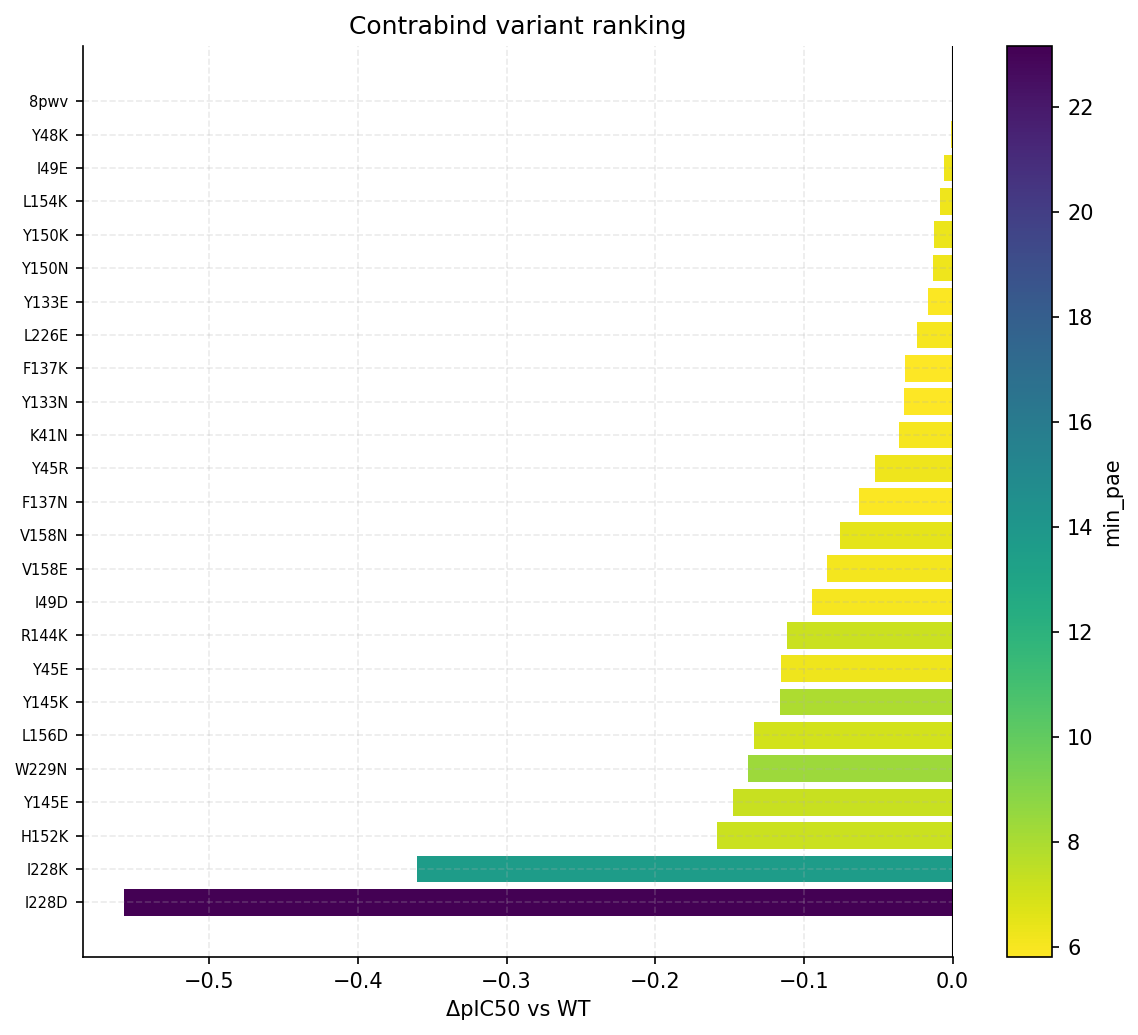

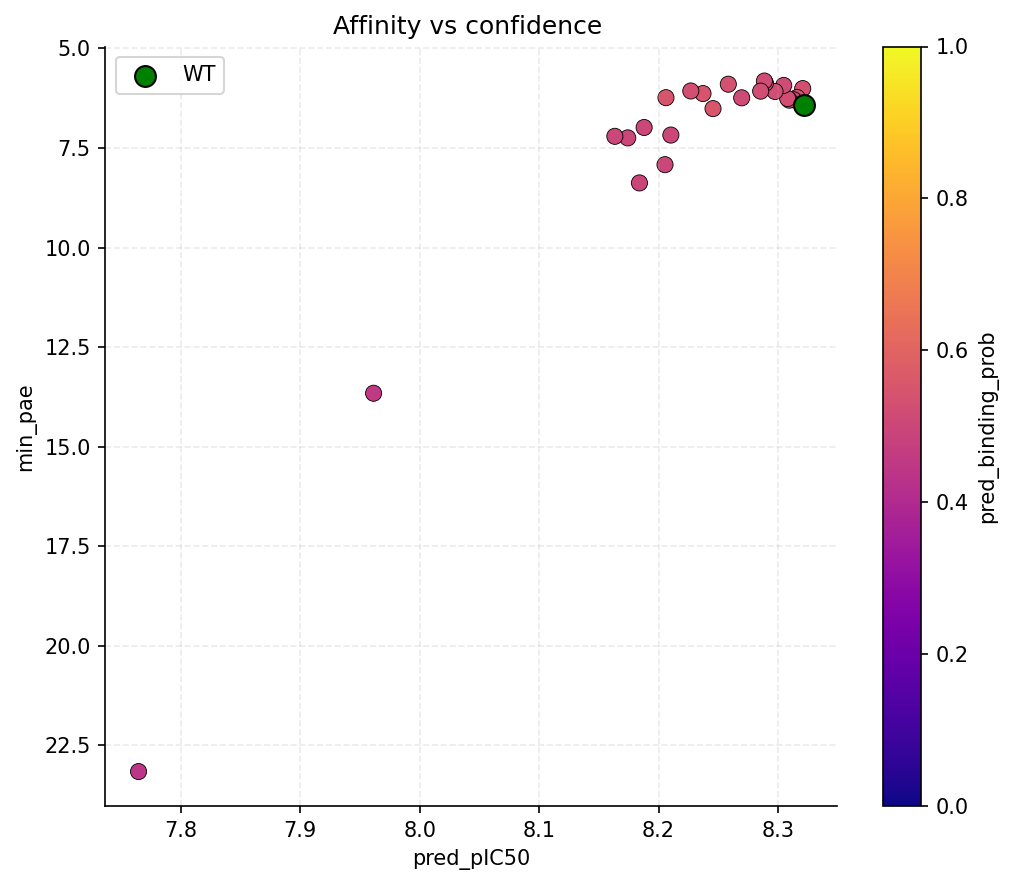

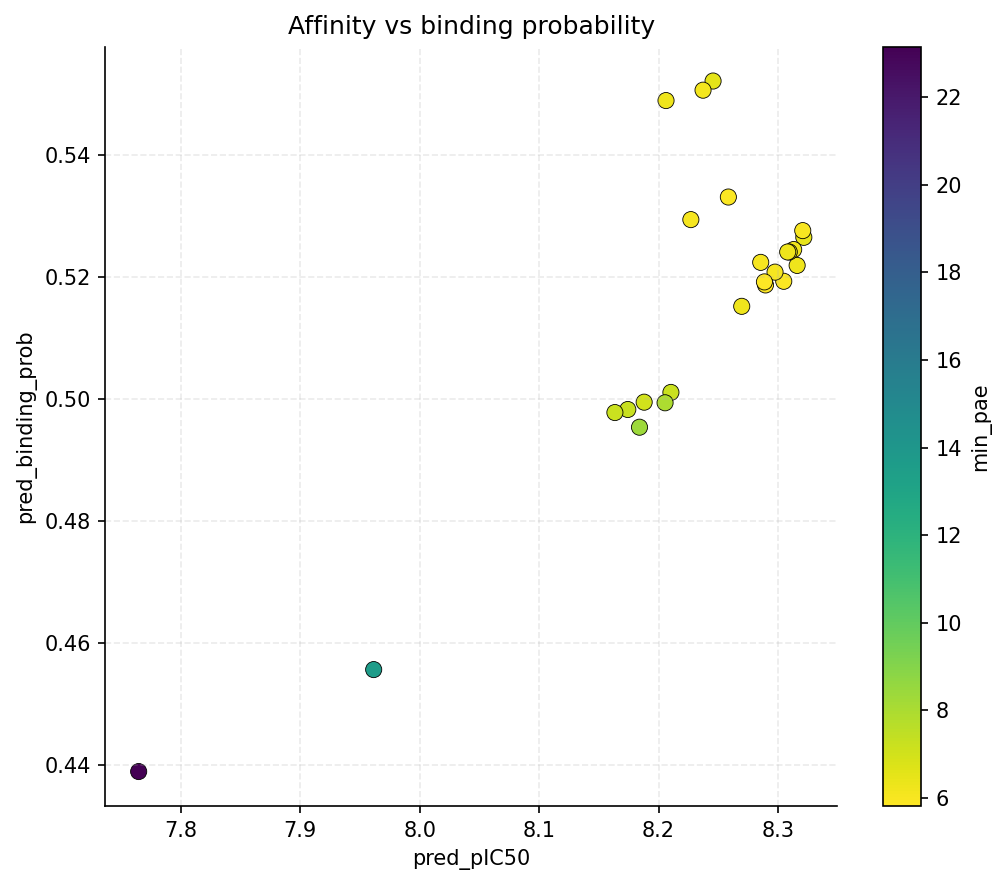

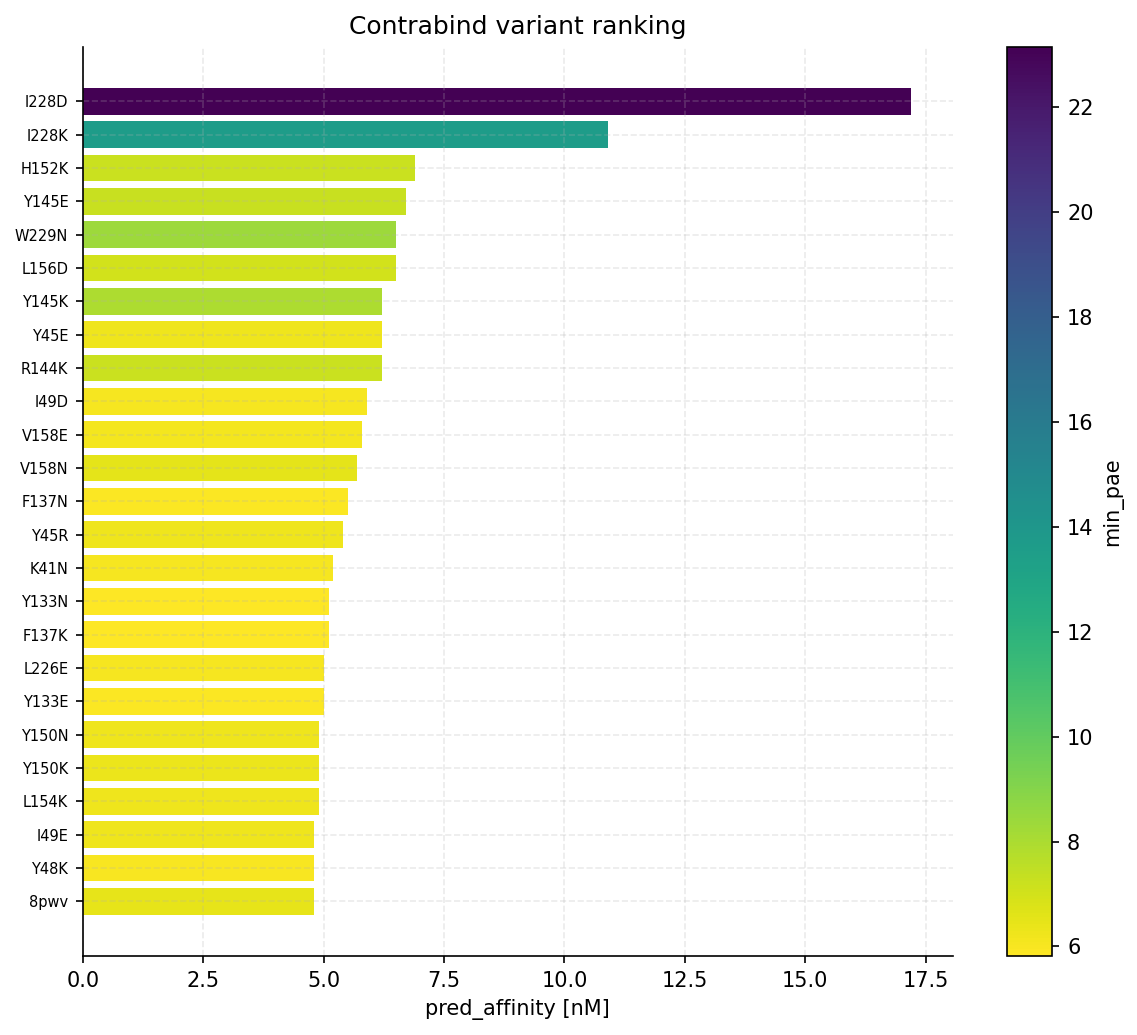

In [19]:
# contrabind visualization script for point mutant rh5 data

#!/usr/bin/env python3
"""
Plot ContraBinding predictions: pIC50, binding probability, and min_pae.
Usage:  python plot_contrabinding.py predictions.csv
Outputs three PNGs in the current directory.
"""
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV      = '/home/llaage/scratch/projects/rh5_folding/260611_contrabinding/contrabinding_out/predictions.csv' #put in your precictions.csv output here
BASELINE = "8pwv"   # name of the WT row; set to None if you didn't run WT

# --- load & tidy -----------------------------------------------------------
df = pd.read_csv(CSV)

# ContraBinding writes both orientations (A:B and B:A). Keep the stronger one.
df = (df.sort_values("pred_pIC50", ascending=False)
        .drop_duplicates("name", keep="first")
        .reset_index(drop=True))

# WT baseline for ΔpIC50 (optional)
base = None
if BASELINE is not None and (df["name"] == BASELINE).any():
    base = float(df.loc[df["name"] == BASELINE, "pred_pIC50"].iloc[0])
    df["delta_pIC50"] = df["pred_pIC50"] - base

label = df["name"].str.replace("8pwv_A_", "", regex=False)

# ============================================================ PLOT 1
# 1. Ranked waterfall: ΔpIC50 (or absolute pIC50), colored by confidence (min_pae)
d = df.sort_values("pred_pIC50")
y = np.arange(len(d))
x = (d["pred_pIC50"] - base) if base is not None else d["pred_pIC50"]
colors = plt.cm.viridis_r(plt.Normalize(d.min_pae.min(), d.min_pae.max())(d.min_pae))

fig, ax = plt.subplots(figsize=(8, max(6, 0.28 * len(d))))
ax.barh(y, x, color=colors)
ax.set_yticks(y); ax.set_yticklabels(d["name"].str.replace("8pwv_A_", "", regex=False), fontsize=7)
ax.set_xlabel("ΔpIC50 vs WT" if base is not None else "pred_pIC50")
ax.set_title("Contrabind variant ranking")
if base is not None:
    ax.axvline(0, color="k", lw=1)                       # WT reference
sm = plt.cm.ScalarMappable(cmap="viridis_r",
        norm=plt.Normalize(d.min_pae.min(), d.min_pae.max()))
fig.colorbar(sm, ax=ax, label="min_pae")
fig.tight_layout(); fig.savefig("plot1_ranking.png", dpi=150)

# ============================================================ PLOT 2
# 2. Affinity vs confidence; color = binding probability. Bottom-right = best.
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(df.pred_pIC50, df.min_pae, c=df.pred_binding_prob,
                cmap="plasma", s=60, edgecolor="k", linewidth=0.4, vmin=0, vmax=1)
ax.invert_yaxis()                                        # so "up" = more confident
ax.set_xlabel("pred_pIC50")
ax.set_ylabel("min_pae")
ax.set_title("Affinity vs confidence ")
if base is not None:
    wt = df[df.name == BASELINE]
    ax.scatter(wt.pred_pIC50, wt.min_pae, s=100,
               color="green", edgecolor="k", zorder=5, label="WT")
    ax.legend()
fig.colorbar(sc, ax=ax, label="pred_binding_prob")
fig.tight_layout(); fig.savefig("plot2_affinity_vs_confidence.png", dpi=150)

# ============================================================ PLOT 3
# 3. Do the two affinity signals agree? color = confidence.
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(df.pred_pIC50, df.pred_binding_prob, c=df.min_pae,
                cmap="viridis_r", s=60, edgecolor="k", linewidth=0.4)
ax.set_xlabel("pred_pIC50")
ax.set_ylabel("pred_binding_prob")
ax.set_title("Affinity vs binding probability")
fig.colorbar(sc, ax=ax, label="min_pae")
fig.tight_layout(); fig.savefig("plot3_pic50_vs_prob.png", dpi=150)

# ============================================================ PLOT 4
# 4. Ranked waterfall: absolute pIC50, colored by confidence (min_pae)
base = None
d = df.sort_values("pred_affinity [nM]")
y = np.arange(len(d))
x = (d["pred_pIC50"] - base) if base is not None else d["pred_affinity [nM]"]
colors = plt.cm.viridis_r(plt.Normalize(d.min_pae.min(), d.min_pae.max())(d.min_pae))

fig, ax = plt.subplots(figsize=(8, max(6, 0.28 * len(d))))
ax.barh(y, x, color=colors)
ax.set_yticks(y); ax.set_yticklabels(d["name"].str.replace("8pwv_A_", "", regex=False), fontsize=7)
ax.set_xlabel("pred_affinity [nM]" if base is not None else "pred_affinity [nM]")
ax.set_title("Contrabind variant ranking")
if base is not None:
    ax.axvline(0, color="k", lw=1)                       # WT reference
sm = plt.cm.ScalarMappable(cmap="viridis_r",
        norm=plt.Normalize(d.min_pae.min(), d.min_pae.max()))
fig.colorbar(sm, ax=ax, label="min_pae")
fig.tight_layout(); fig.savefig("plot4_ranking.png", dpi=150)

print("Saved: plot1_ranking.png, plot2_affinity_vs_confidence.png, plot3_pic50_vs_prob.png")


# 3. comparison ddG, contrabind, BLI

In [ ]:
INPUT_FILE = '/home/llaage/projects/presentations/contra_ddg_BLI.xlsx'      # Change to your data file (CSV or XLSX)
OUTPUT_FILE = '/home/llaage/projects/presentations/mutation_analysis.png'  # Change to your desired output filename

Loading data from /home/llaage/projects/presentations/contra_ddg_BLI.xlsx...
✓ Loaded 25 mutations
Creating visualization...
✓ Figure saved to: /home/llaage/projects/presentations/mutation_analysis.png


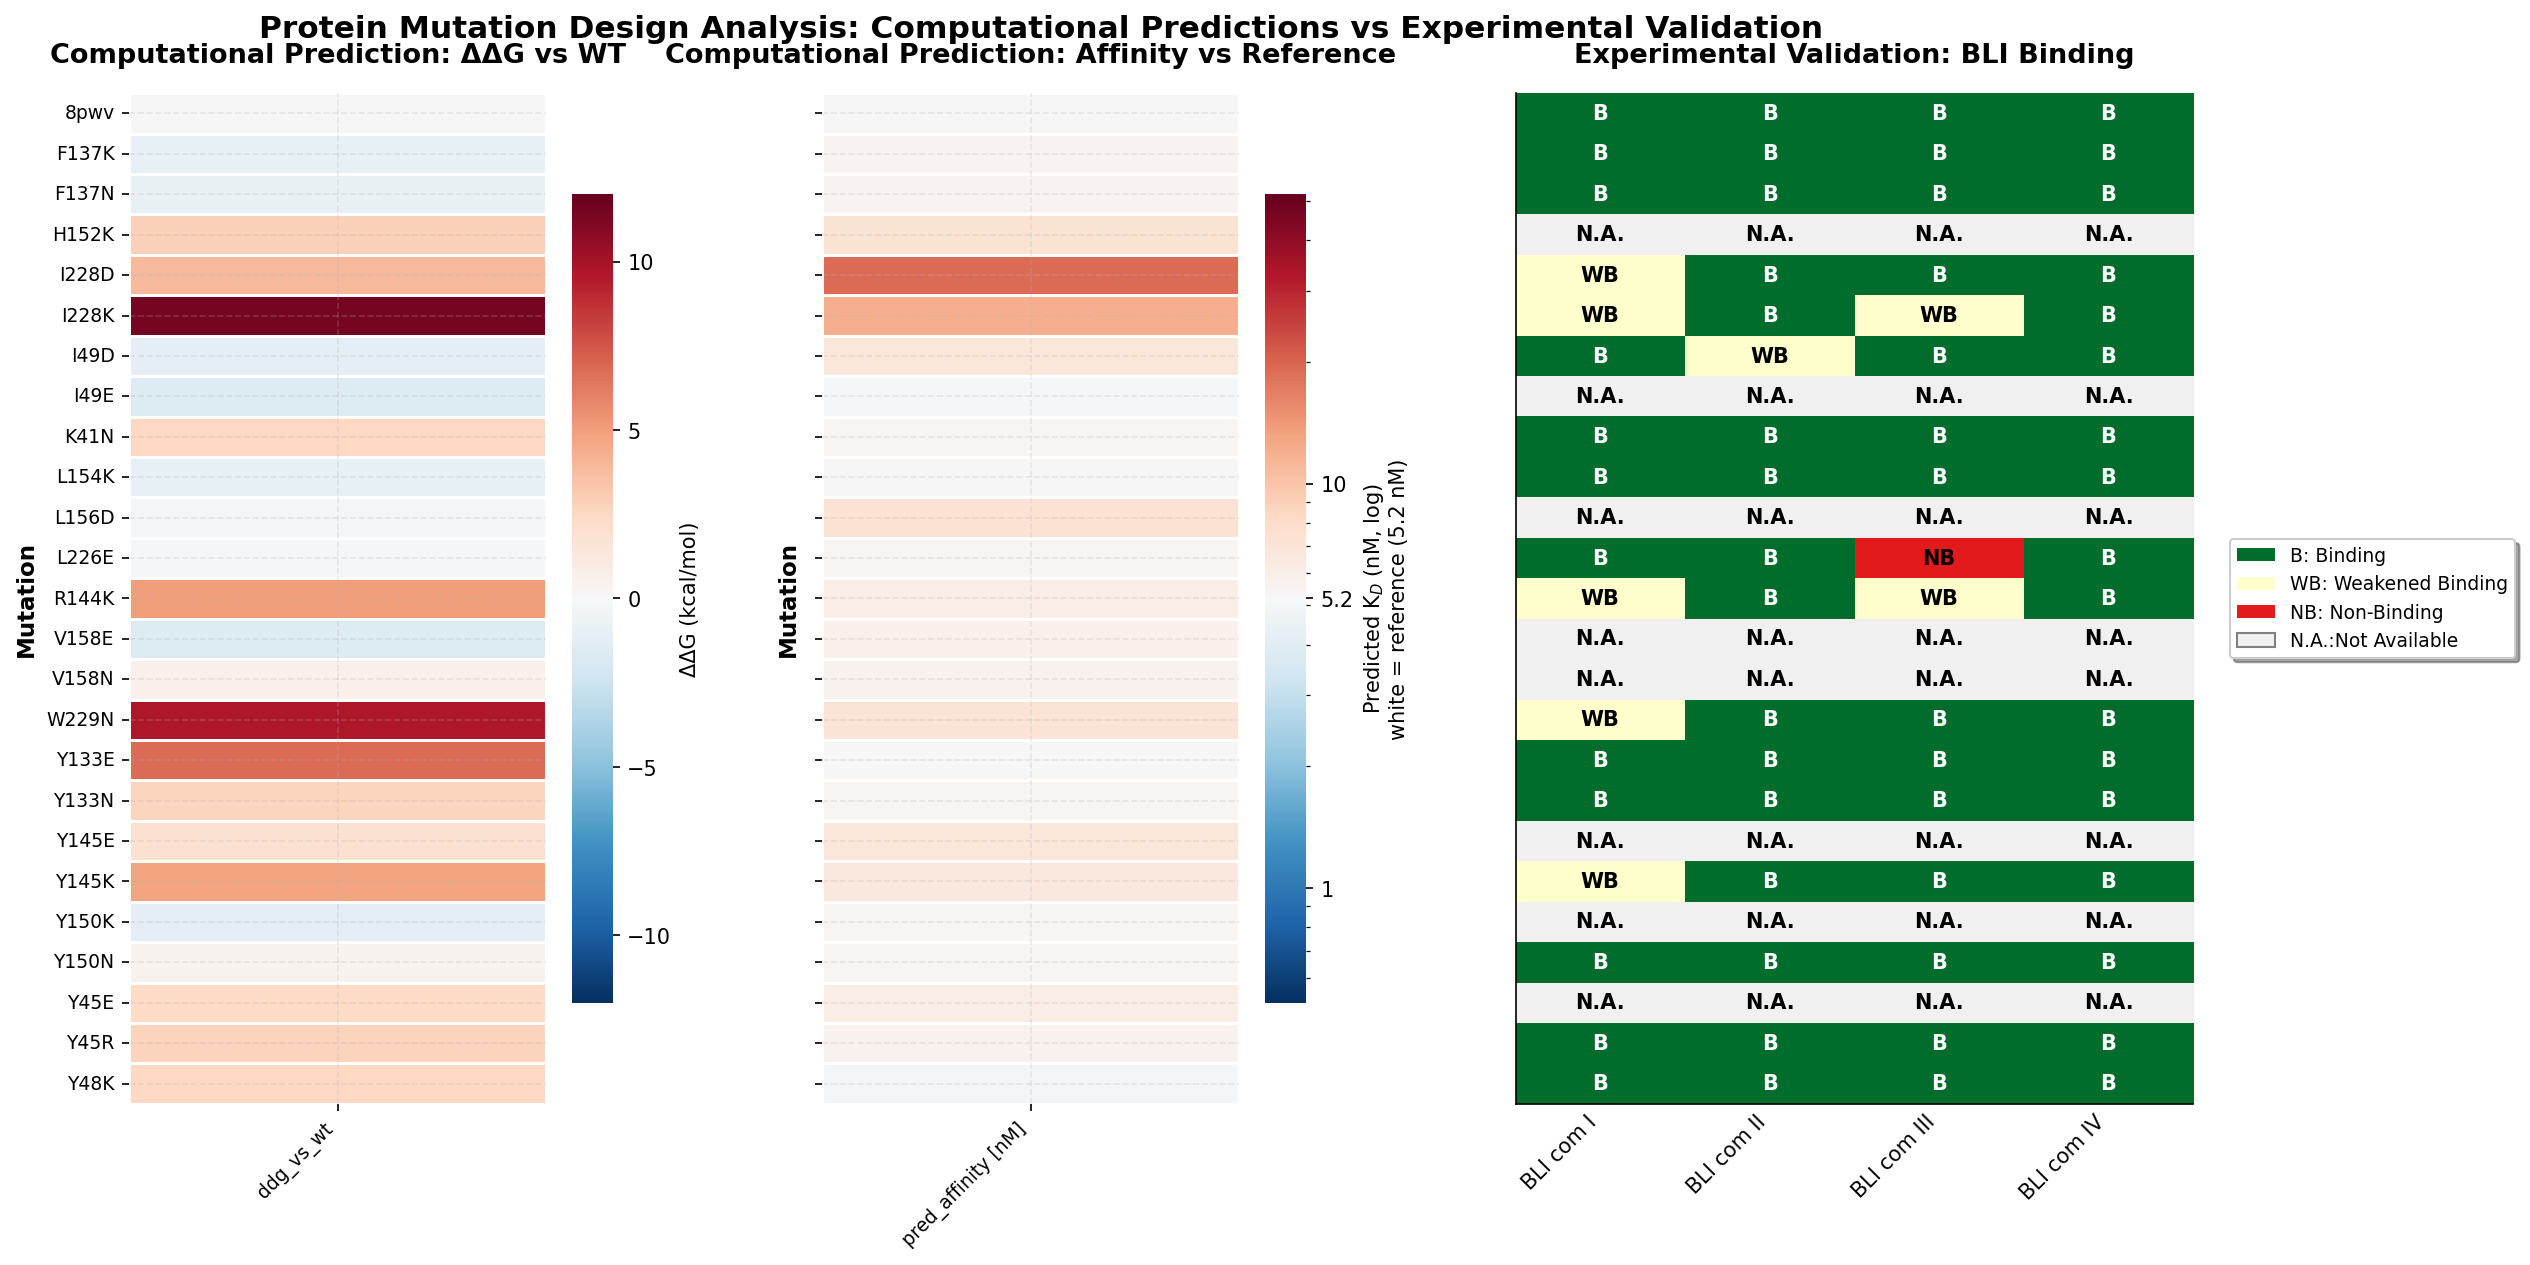

✓ Done! Output saved to: /home/llaage/projects/presentations/mutation_analysis.png


In [35]:
#!/usr/bin/env python3
"""
Protein Mutation Design Visualization Script
Generates a comprehensive heatmap visualization of computational predictions and experimental validation data
"""

import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm, LogNorm
import seaborn as sns
from pathlib import Path

# ============================================================================
# CONFIGURATION - MODIFY THESE PATHS FOR YOUR DATA
# ============================================================================
INPUT_FILE = '/home/llaage/projects/presentations/contra_ddg_BLI.xlsx'      # Change to your data file (CSV or XLSX)
OUTPUT_FILE = '/home/llaage/projects/presentations/mutation_analysis.png'  # Change to your desired output filename

# --- Color scale ranges (tune to your data) ---
# ddG: white is fixed at 0 (wild-type); blue = stabilizing, red = destabilizing.
# Range kept symmetric (-12..12) so the panel is scientifically honest about the
# theoretical scale even though observed values are smaller.
DDG_MIN = -12     # most stabilizing value (dark blue end)
DDG_MAX = 12      # most destabilizing value (dark red end)

# Affinity uses a LOG scale anchored to a biological REFERENCE Kd ("vs reference"),
# making it a direct parallel to the "ddG vs WT" panel:
#   white = reference Kd  |  blue = tighter than reference  |  red = weaker than reference
# Because dG = RT*ln(Kd), equal color steps = equal binding-energy steps.
#
# >>> SET THIS to your parent/target antibody Kd. <<<
# If you have no reference, pick a meaningful benchmark (e.g. 10 nM) and treat the
# panel as absolute; the colorbar still reads correctly in nM.
REFERENCE_KD_NM = 5.2   # parent/target Kd in nM -> the white pivot
AFFINITY_SPAN_DECADES = 1  # log10 decades shown on EACH side of the reference
# ============================================================================

# Derived affinity limits (symmetric in log space => white lands exactly on the reference)
AFFINITY_MIN_NM = REFERENCE_KD_NM / (10 ** AFFINITY_SPAN_DECADES)  # tightest (dark blue end)
AFFINITY_MAX_NM = REFERENCE_KD_NM * (10 ** AFFINITY_SPAN_DECADES)  # weakest (dark red end)


def load_data(file_path):
    """Load data from XLSX or CSV file"""
    if file_path.endswith('.xlsx'):
        df = pd.read_excel(file_path)
    else:
        df = pd.read_csv(file_path)
    return df


def clean_mutation_names(df):
    """Remove prefix (e.g., '8pwv_A_') from mutation names"""
    df['mutation'] = df['mutation'].str.replace(r'^[^_]+_[^_]+_', '', regex=True)
    return df


def validate_data(df):
    """Validate that required columns are present"""
    required_cols = ['mutation', 'ddg_vs_wt', 'pred_affinity [nM]',
                     'BLI com I', 'BLI com II', 'BLI com III', 'BLI com IV']
    missing = [col for col in required_cols if col not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    return True


def create_diverging_colormap():
    """
    Shared diverging blue-white-red colormap used for BOTH heatmap panels
    so the two plots use exactly the same colors.

    Interpretation in both panels (each has a meaningful neutral pivot at white):
      - Dark blue  = favorable    (stabilizing ddG  / tighter than reference Kd)
      - White      = neutral       (ddG = 0          / equal to reference Kd)
      - Dark red   = unfavorable   (destabilizing ddG/ weaker than reference Kd)

    Uses the ColorBrewer RdBu endpoints (dark navy <-> dark maroon) reversed
    so that low values are blue and high values are red.
    """
    colors = ['#053061', '#2166ac', '#4393c3', '#92c5de', '#d1e5f0',
              '#f7f7f7',
              '#fddbc7', '#f4a582', '#d6604d', '#b2182b', '#67001f']
    return LinearSegmentedColormap.from_list('div_bwr', colors, N=256)


def prepare_heatmap_data(df):
    """Prepare data for heatmap visualization"""
    # Set mutation as index
    df_plot = df.set_index('mutation').copy()

    # Extract the three categories
    ddg_data = df_plot[['ddg_vs_wt']]
    affinity_data = df_plot[['pred_affinity [nM]']]
    bli_data = df_plot[['BLI com I', 'BLI com II', 'BLI com III', 'BLI com IV']]

    return ddg_data, affinity_data, bli_data


def convert_bli_to_numeric(bli_value):
    """Convert BLI categorical data to numeric for visualization
    Mapping: b (binding/desired) = 3, wb (weakened) = 1.5, nb (non-binding) = 0, n.a. = NaN
    """
    mapping = {'b': 3, 'wb': 1.5, 'nb': 0, 'n.a.': np.nan}
    if isinstance(bli_value, str):
        return mapping.get(bli_value.strip().lower(), np.nan)
    return np.nan


def create_bli_colormap():
    """Create biologically intuitive colormap for BLI data
    Red (Non-Binding) -> Yellow (Weakened) -> Green (Binding/Desired)
    Consistent with heatmap scheme: cool colors = good, warm colors = bad
    """
    colors = ['#e31a1c', '#fd8d3c', '#ffffcc', '#2ca25f', '#006d2c']  # Red -> Orange -> Yellow -> Green -> Dark Green
    return LinearSegmentedColormap.from_list('bli_cmap', colors, N=256)


def affinity_colorbar_ticks(vmin, vmax, reference):
    """Power-of-ten ticks within range, guaranteeing the reference Kd is marked."""
    lo = math.floor(math.log10(vmin))
    hi = math.ceil(math.log10(vmax))
    ticks = [10 ** e for e in range(lo, hi + 1) if vmin <= 10 ** e <= vmax]
    if not any(abs(t - reference) < 1e-9 for t in ticks):
        ticks = sorted(ticks + [reference])
    return ticks


def create_visualization(df, output_path='mutation_analysis.png', dpi=300):
    """
    Create comprehensive mutation analysis visualization
    """
    # Validate and prepare data
    validate_data(df)
    df = clean_mutation_names(df)
    ddg_data, affinity_data, bli_data = prepare_heatmap_data(df)

    # Convert BLI data to numeric
    # Use DataFrame.map (applymap was deprecated in pandas 2.1.0 and removed in later versions)
    try:
        bli_numeric = bli_data.map(convert_bli_to_numeric)
    except AttributeError:
        # Fallback for pandas < 2.1.0 where DataFrame.map doesn't exist
        bli_numeric = bli_data.applymap(convert_bli_to_numeric)

    # Set up the figure with custom layout
    fig = plt.figure(figsize=(16, max(8, len(df) * 0.35)))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.3], wspace=0.3,
                          left=0.12, right=0.98, top=0.92, bottom=0.15)

    # Get shared colormap (identical colors for both heatmap panels)
    div_cmap = create_diverging_colormap()

    # --- PANEL 1: ddG vs WT ---
    ax1 = fig.add_subplot(gs[0])

    # Center white exactly at 0 (wild-type): blue = stabilizing, red = destabilizing
    ddg_norm = TwoSlopeNorm(vmin=DDG_MIN, vcenter=0, vmax=DDG_MAX)

    sns.heatmap(ddg_data, cmap=div_cmap, norm=ddg_norm, ax=ax1,
                cbar_kws={'label': 'ΔΔG (kcal/mol)', 'shrink': 0.8},
                linewidths=0.5, linecolor='white')

    ax1.set_title('Computational Prediction: ΔΔG vs WT', fontsize=13, fontweight='bold', pad=15)
    ax1.set_xlabel('')
    ax1.set_ylabel('Mutation', fontsize=11, fontweight='bold')
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, fontsize=9)

    # --- PANEL 2: Predicted Affinity vs Reference (log scale) ---
    ax2 = fig.add_subplot(gs[1])

    # Log scale anchored on the reference Kd:
    #   white = reference | blue = tighter | red = weaker
    affinity_norm = LogNorm(vmin=AFFINITY_MIN_NM, vmax=AFFINITY_MAX_NM)

    sns.heatmap(affinity_data, cmap=div_cmap, norm=affinity_norm, ax=ax2,
                cbar_kws={'label': f'Predicted K$_D$ (nM, log)\nwhite = reference ({REFERENCE_KD_NM:g} nM)',
                          'shrink': 0.8},
                linewidths=0.5, linecolor='white')

    # Clean, readable log-spaced colorbar ticks (reference always marked)
    cbar2 = ax2.collections[0].colorbar
    ticks = affinity_colorbar_ticks(AFFINITY_MIN_NM, AFFINITY_MAX_NM, REFERENCE_KD_NM)
    cbar2.set_ticks(ticks)
    cbar2.set_ticklabels([f'{t:g}' for t in ticks])

    ax2.set_title('Computational Prediction: Affinity vs Reference', fontsize=13, fontweight='bold', pad=15)
    ax2.set_xlabel('')
    ax2.set_ylabel('Mutation', fontsize=11, fontweight='bold')
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax2.set_yticklabels([])

    # --- PANEL 3: BLI Binding Data ---
    ax3 = fig.add_subplot(gs[2])

    # Create annotation text for categorical data
    bli_annotations = np.empty_like(bli_numeric, dtype=object)
    for i in range(bli_data.shape[0]):
        for j in range(bli_data.shape[1]):
            bli_annotations[i, j] = str(bli_data.iloc[i, j])

    # Plot with numeric data for color gradient
    # N.A. values (NaN) render as light gray to match the legend
    bli_cmap = create_bli_colormap()
    bli_cmap.set_bad('#f0f0f0')
    bli_norm = Normalize(vmin=0, vmax=3)
    # interpolation='nearest' prevents faint antialiasing lines between adjacent same-color cells
    im3 = ax3.imshow(bli_numeric.values, cmap=bli_cmap, norm=bli_norm,
                     aspect='auto', interpolation='nearest')

    # Add text annotations
    for i in range(bli_data.shape[0]):
        for j in range(bli_data.shape[1]):
            text_val = bli_annotations[i, j]
            # Choose text color for readability
            color = 'white' if bli_numeric.iloc[i, j] > 1.5 else 'black'
            ax3.text(j, i, text_val.upper(), ha='center', va='center',
                     color=color, fontweight='bold', fontsize=10)

    ax3.set_xticks(np.arange(len(bli_data.columns)))
    ax3.set_yticks(np.arange(len(bli_data.index)))
    ax3.set_xticklabels(bli_data.columns, rotation=45, ha='right', fontsize=10)
    ax3.set_yticklabels([])
    ax3.tick_params(length=0)        # remove tick marks
    ax3.grid(False)                  # ensure no gridlines in cells
    ax3.set_title('Experimental Validation: BLI Binding', fontsize=13, fontweight='bold', pad=15)

    # Legend for BLI categories (green=binding, yellow=weakened, red=non-binding, gray=n.a.)
    legend_elements = [
        mpatches.Patch(facecolor='#006d2c', label='B: Binding'),
        mpatches.Patch(facecolor='#ffffcc', label='WB: Weakened Binding'),
        mpatches.Patch(facecolor='#e31a1c', label='NB: Non-Binding'),
        mpatches.Patch(facecolor='#f0f0f0', label='N.A.:Not Available', edgecolor='gray')
    ]
    ax3.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.04, 0.5),
               fontsize=9, frameon=True, fancybox=True, shadow=True)

    # Overall title
    fig.suptitle('Protein Mutation Design Analysis: Computational Predictions vs Experimental Validation',
                 fontsize=15, fontweight='bold', y=0.98)

    # Save figure
    plt.savefig(output_path, dpi=dpi, bbox_inches='tight', facecolor='white')
    print(f"✓ Figure saved to: {output_path}")
    plt.show()

    return fig


def main():
    """Main execution function - uses INPUT_FILE and OUTPUT_FILE from configuration at top"""

    # Check if file exists
    if not Path(INPUT_FILE).exists():
        print(f"✗ Error: File '{INPUT_FILE}' not found")
        print("\n⚠️  UPDATE CONFIGURATION:")
        print(f"  Set INPUT_FILE = 'path/to/your/data.csv' at the top of the script")
        return

    try:
        print(f"Loading data from {INPUT_FILE}...")
        df = load_data(INPUT_FILE)
        print(f"✓ Loaded {len(df)} mutations")

        print("Creating visualization...")
        create_visualization(df, output_path=OUTPUT_FILE, dpi=300)
        print(f"✓ Done! Output saved to: {OUTPUT_FILE}")

    except Exception as e:
        print(f"✗ Error: {str(e)}")
        raise

# ============================================================================
# RUN THE VISUALIZATION
# ============================================================================
if __name__ == '__main__':
    main()

# For Jupyter notebook users: uncomment the line below to run directly in a cell
# main()

In [ ]:
#test
